# Lab 7- Data Analysis


In [15]:
%pip install pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 49.9 MB/s eta 0:00:00MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl (20.5 MB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 5150760
-rw-r--r--  1 safal  staff   357K Oct 23 19:04 Lab.7.ipynb
-rw-r--r--  1 safal  staff   149K Oct 23 18:52 Lab.7.pdf
-rw-r--r--  1 safal  staff   228M Oct 23 19:00 SUSY-small.csv
-rw-r--r--  1 safal  staff   2.2G Oct 23 18:59 SUSY.csv


The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 5150760
-rw-r--r--  1 safal  staff   357K Oct 23 19:04 Lab.7.ipynb
-rw-r--r--  1 safal  staff   149K Oct 23 18:52 Lab.7.pdf
-rw-r--r--  1 safal  staff   228M Oct 23 19:00 SUSY-small.csv
-rw-r--r--  1 safal  staff   2.2G Oct 23 18:59 SUSY.csv


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 5175552
-rw-r--r--  1 safal  staff   357K Oct 23 19:04 Lab.7.ipynb
-rw-r--r--  1 safal  staff   149K Oct 23 18:52 Lab.7.pdf
-rw-r--r--  1 safal  staff   228M Oct 23 19:04 SUSY-small.csv
-rw-r--r--  1 safal  staff   2.2G Oct 23 18:59 SUSY.csv


In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['R',
 'dPhi_r_b',
 'MT2',
 'cos_theta_r1',
 'M_TR_2',
 'M_Delta_R',
 'MET_rel',
 'S_R',
 'M_R',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,1.0,0.853325,-0.961783,-1.487277,0.678190,0.493580,1.647969,1.843867,0.276954,1.025105,-1.486535,0.892879,1.684429,1.674084,3.366298,1.046707,2.646649,1.389226,0.364599
4999996,0.0,0.951581,0.139370,1.436884,0.880440,-0.351948,-0.740852,0.290863,-0.732360,0.001360,0.257738,0.802871,0.545319,0.602730,0.002998,0.748959,0.401166,0.443471,0.239953
4999997,0.0,0.840389,1.419162,-1.218766,1.195631,1.695645,0.663756,0.490888,-0.509186,0.704289,0.045744,0.825015,0.723530,0.778236,0.752942,0.838953,0.614048,1.210595,0.026692
4999998,1.0,1.784218,-0.833565,-0.560091,0.953342,-0.688969,-1.428233,2.660703,-0.861344,2.116892,2.906151,1.232334,0.952444,0.685846,0.000000,0.781874,0.676003,1.197807,0.093689


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


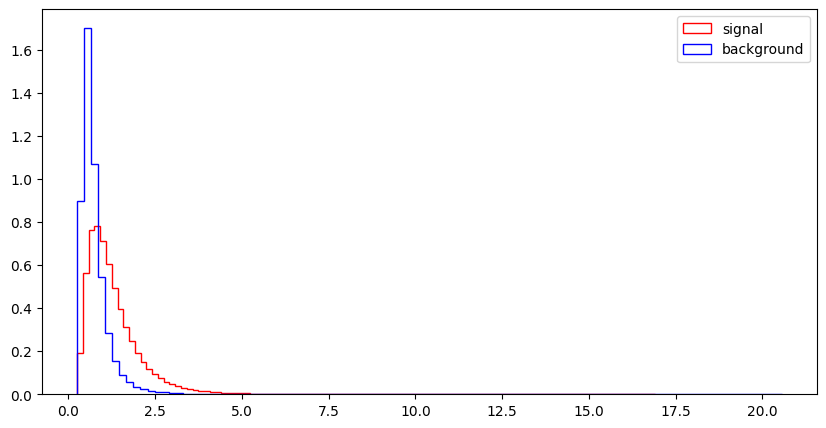

l_1_eta


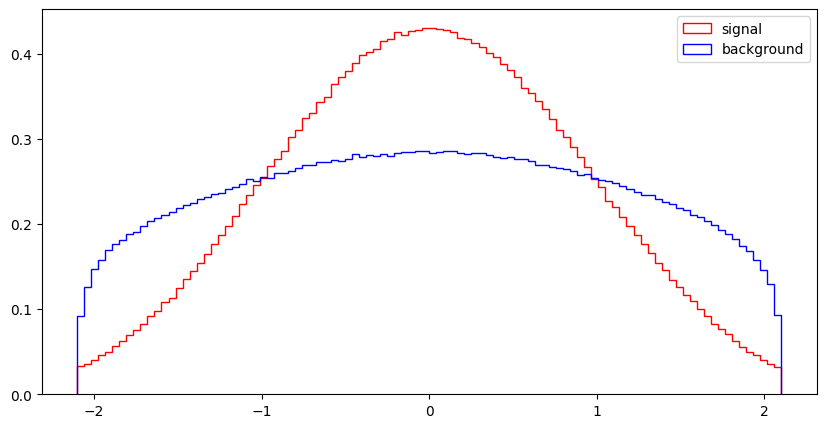

l_1_phi


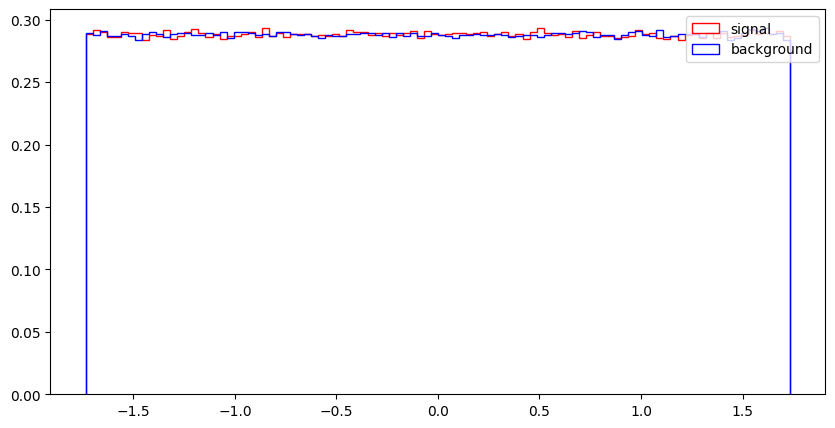

l_2_pT


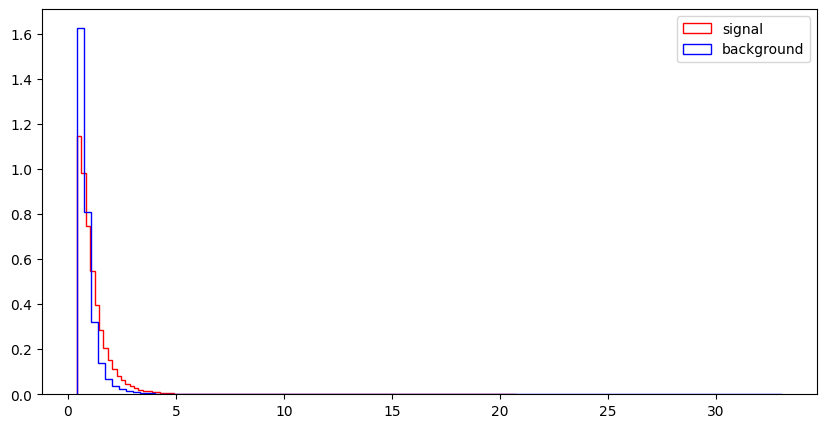

l_2_eta


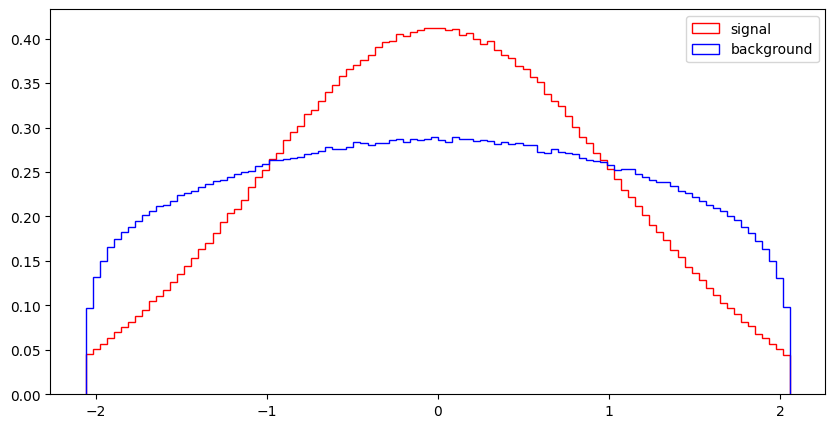

l_2_phi


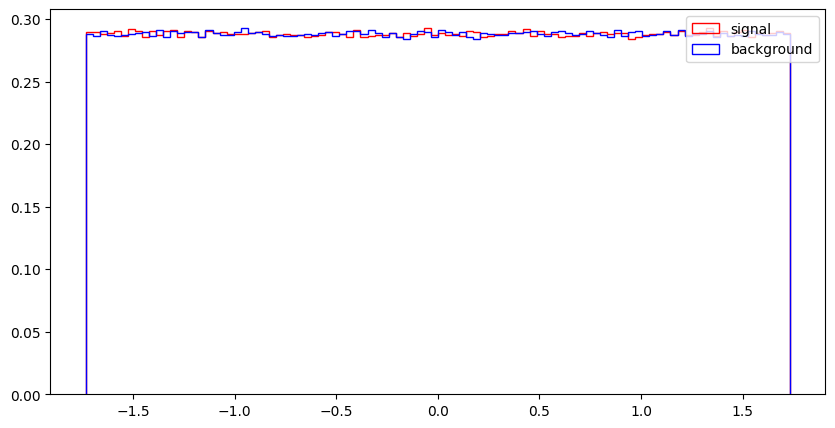

MET


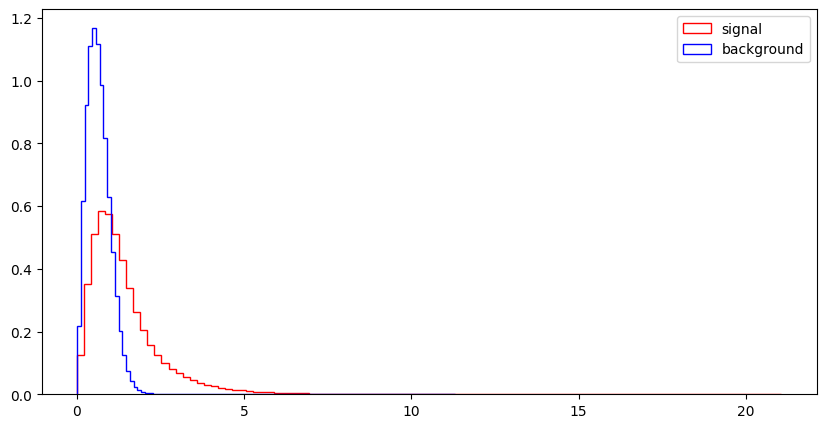

MET_phi


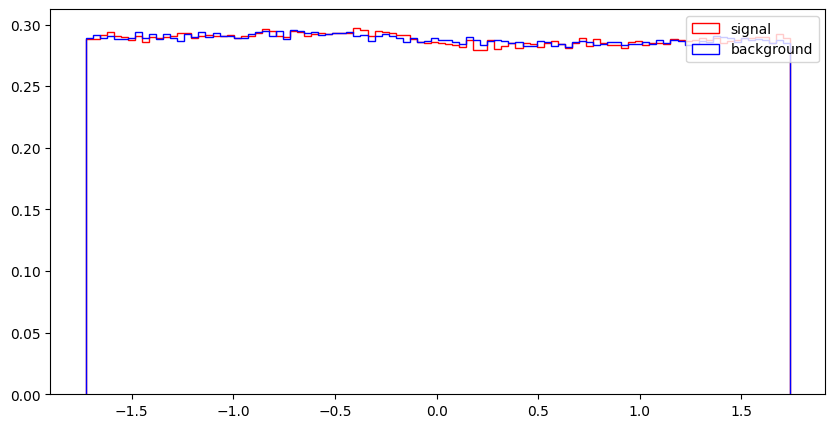

MET_rel


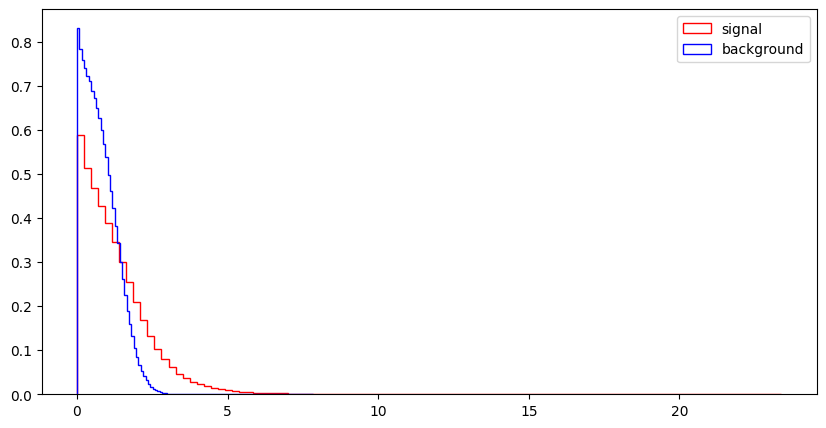

axial_MET


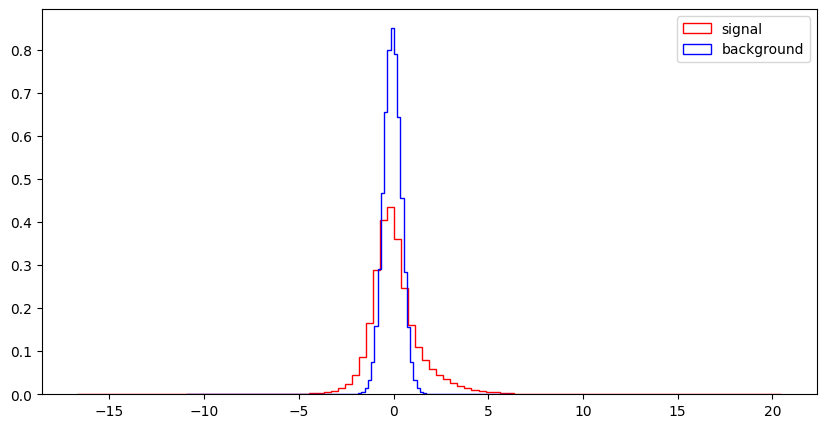

M_R


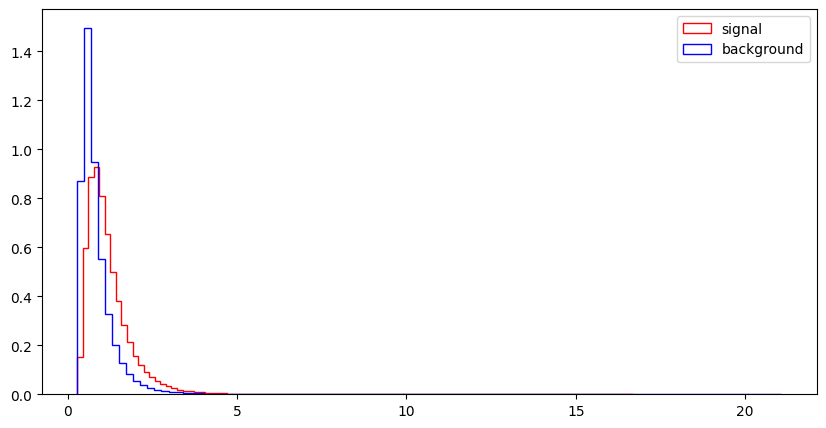

M_TR_2


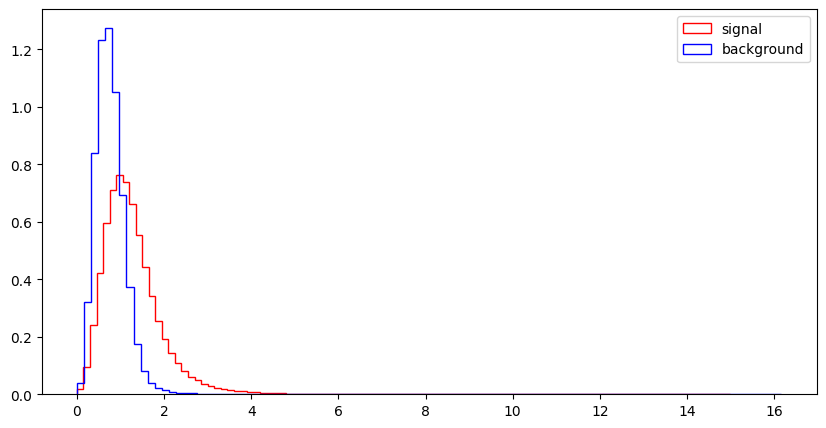

R


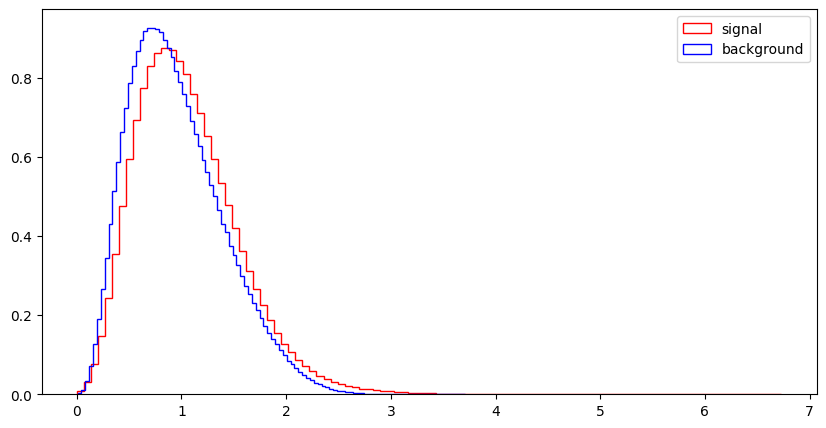

MT2


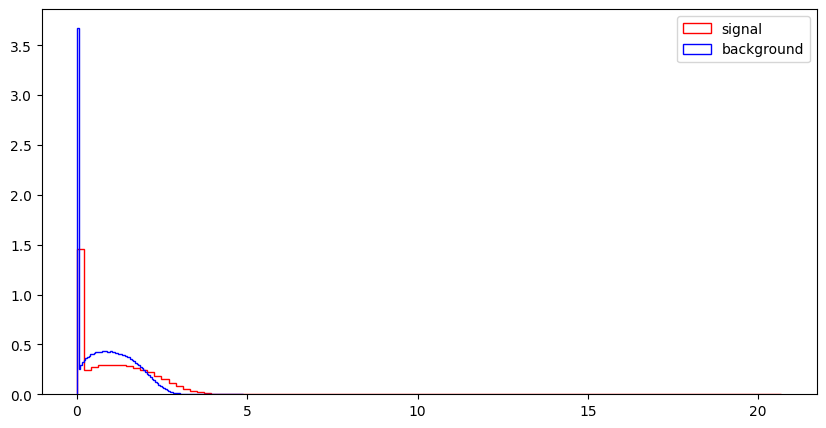

S_R


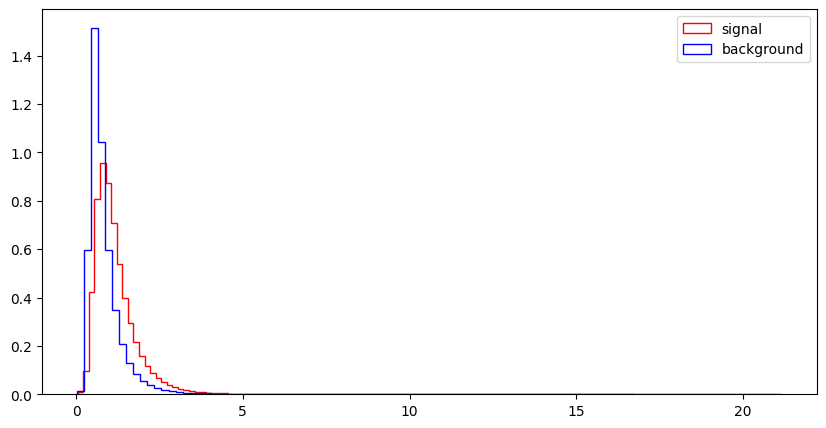

M_Delta_R


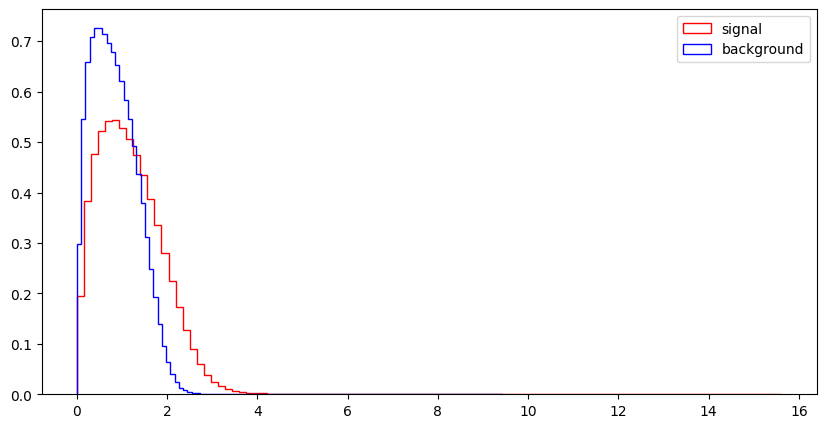

dPhi_r_b


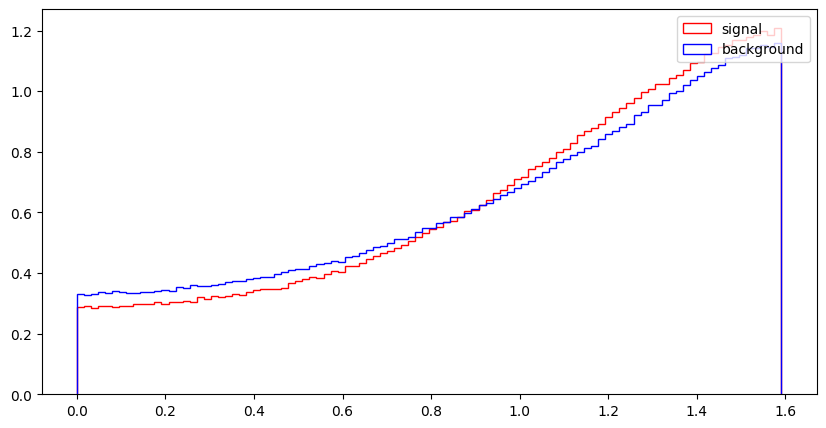

cos_theta_r1


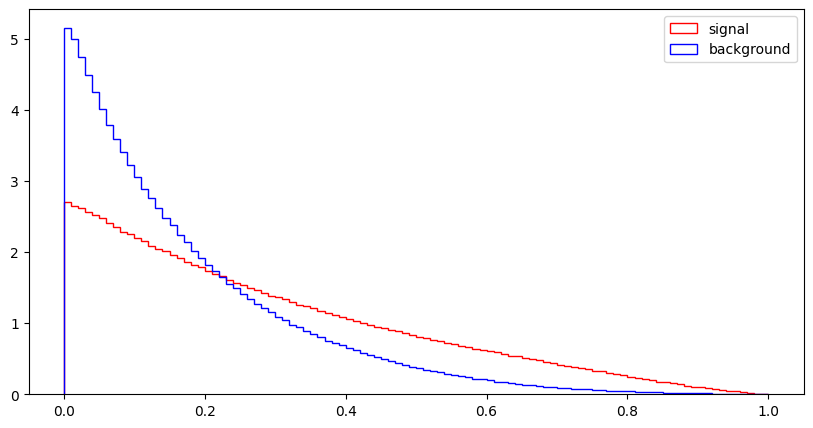

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

Dataset shape: (500000, 19)
Signal events: 229245
Background events: 270755


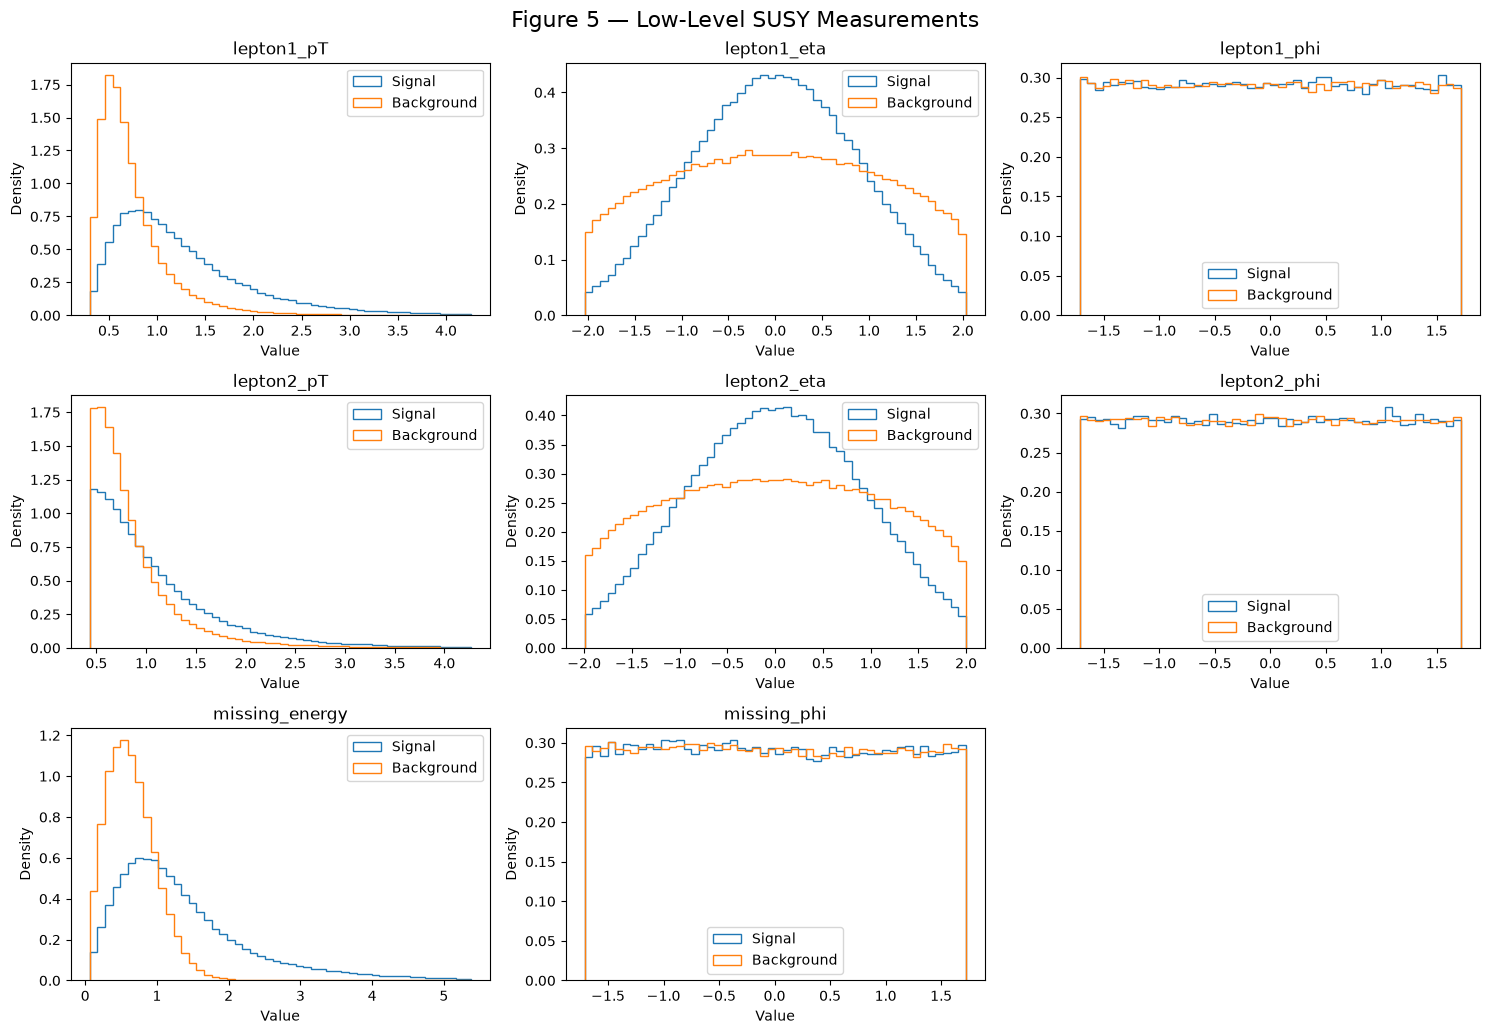

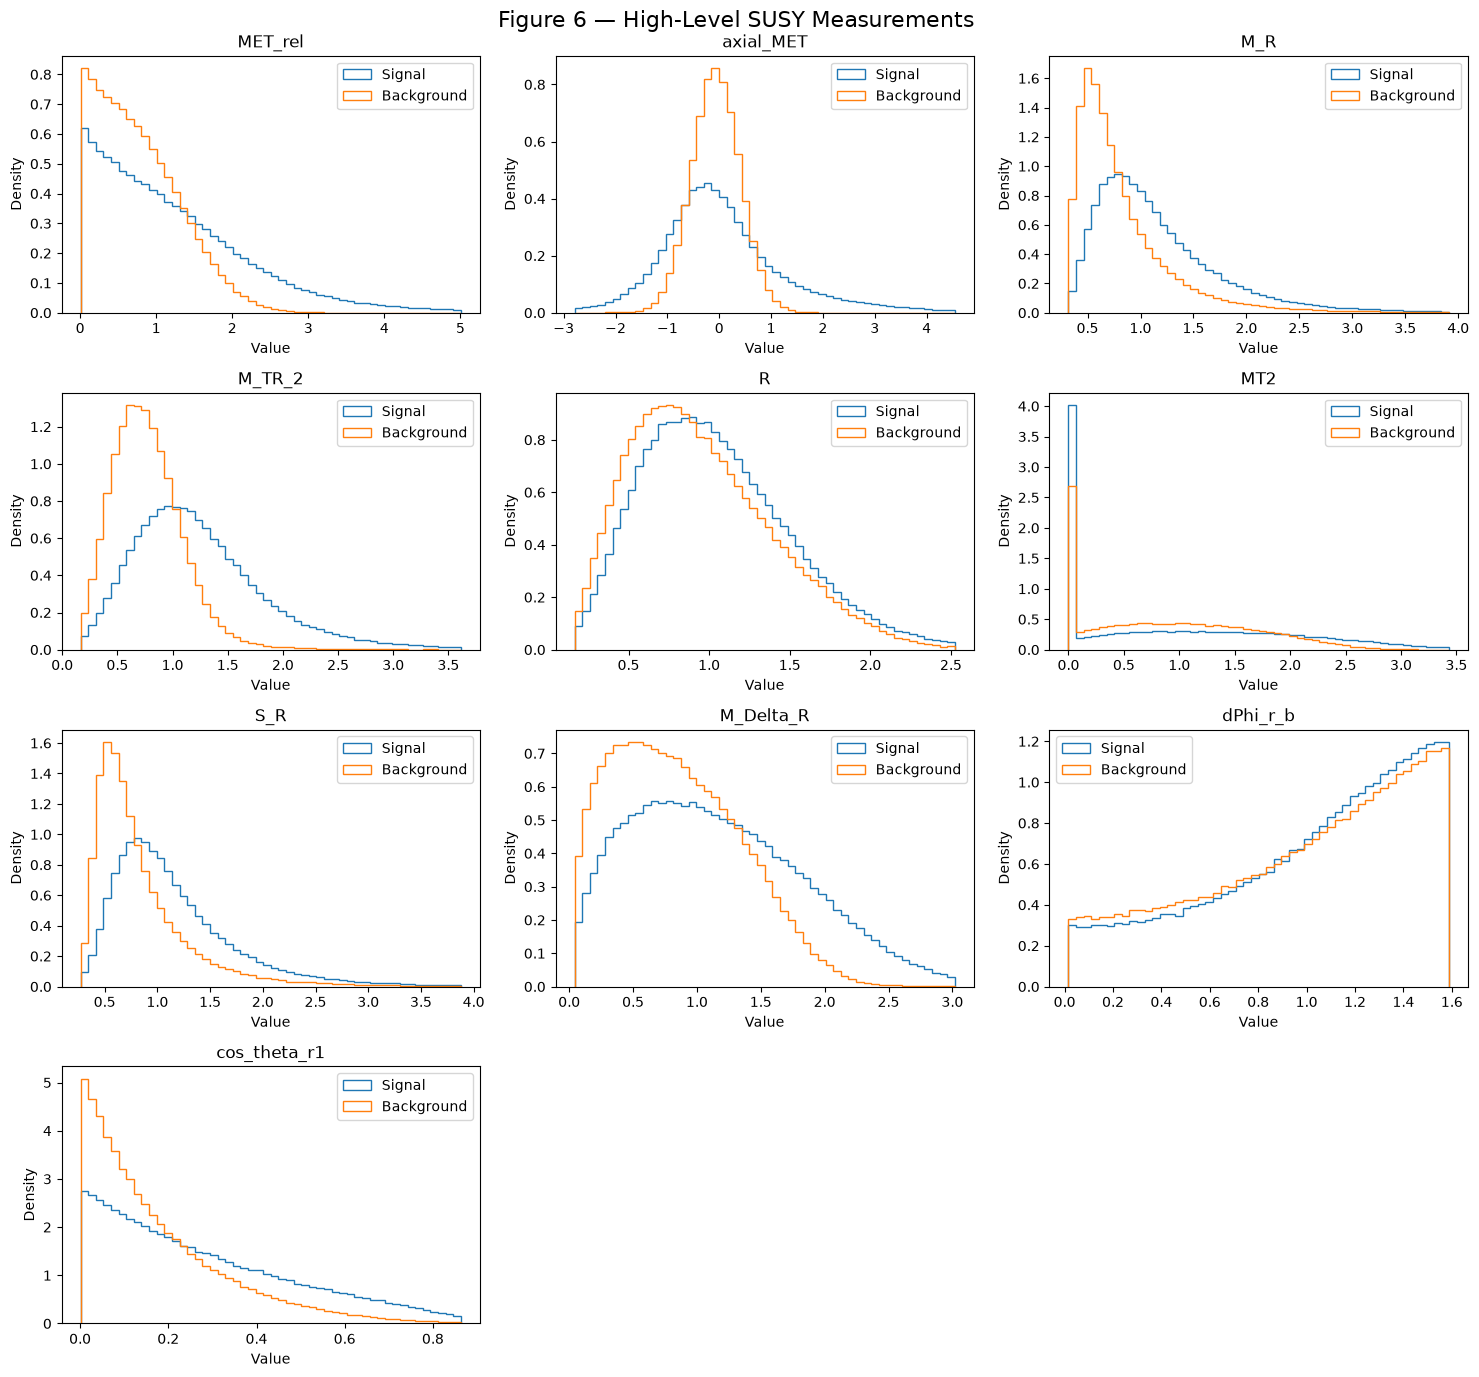

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RawNames = [
    'lepton1_pT', 'lepton1_eta', 'lepton1_phi',
    'lepton2_pT', 'lepton2_eta', 'lepton2_phi',
    'missing_energy', 'missing_phi'
]

FeatureNames = [
    'MET_rel', 'axial_MET', 'M_R', 'M_TR_2',
    'R', 'MT2', 'S_R', 'M_Delta_R',
    'dPhi_r_b', 'cos_theta_r1'
]

AllNames = ['label'] + RawNames + FeatureNames


df = pd.read_csv('SUSY-small.csv', header=None, names=AllNames)

df_sig = df[df['label'] == 1]
df_bkg = df[df['label'] == 0]

print("Dataset shape:", df.shape)
print("Signal events:", len(df_sig))
print("Background events:", len(df_bkg))

def distribution_grid(columns, title, bins=50):
    ncols = 3
    nrows = int(np.ceil(len(columns) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 3.5 * nrows)
    )

    axes = np.asarray(axes).ravel()

    for ax, col in zip(axes, columns):
        lo, hi = np.quantile(df[col], [0.005, 0.995])

        ax.hist(
            df_sig[col],
            bins=bins,
            range=(lo, hi),
            density=True,
            histtype='step',
            label='Signal'
        )

        ax.hist(
            df_bkg[col],
            bins=bins,
            range=(lo, hi),
            density=True,
            histtype='step',
            label='Background'
        )

        ax.set_title(col)
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
        ax.legend()

    for ax in axes[len(columns):]:
        ax.axis('off')

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


distribution_grid(
    RawNames,
    'Figure 5 — Low-Level SUSY Measurements'
)


distribution_grid(
    FeatureNames,
    'Figure 6 — High-Level SUSY Measurements'
)

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

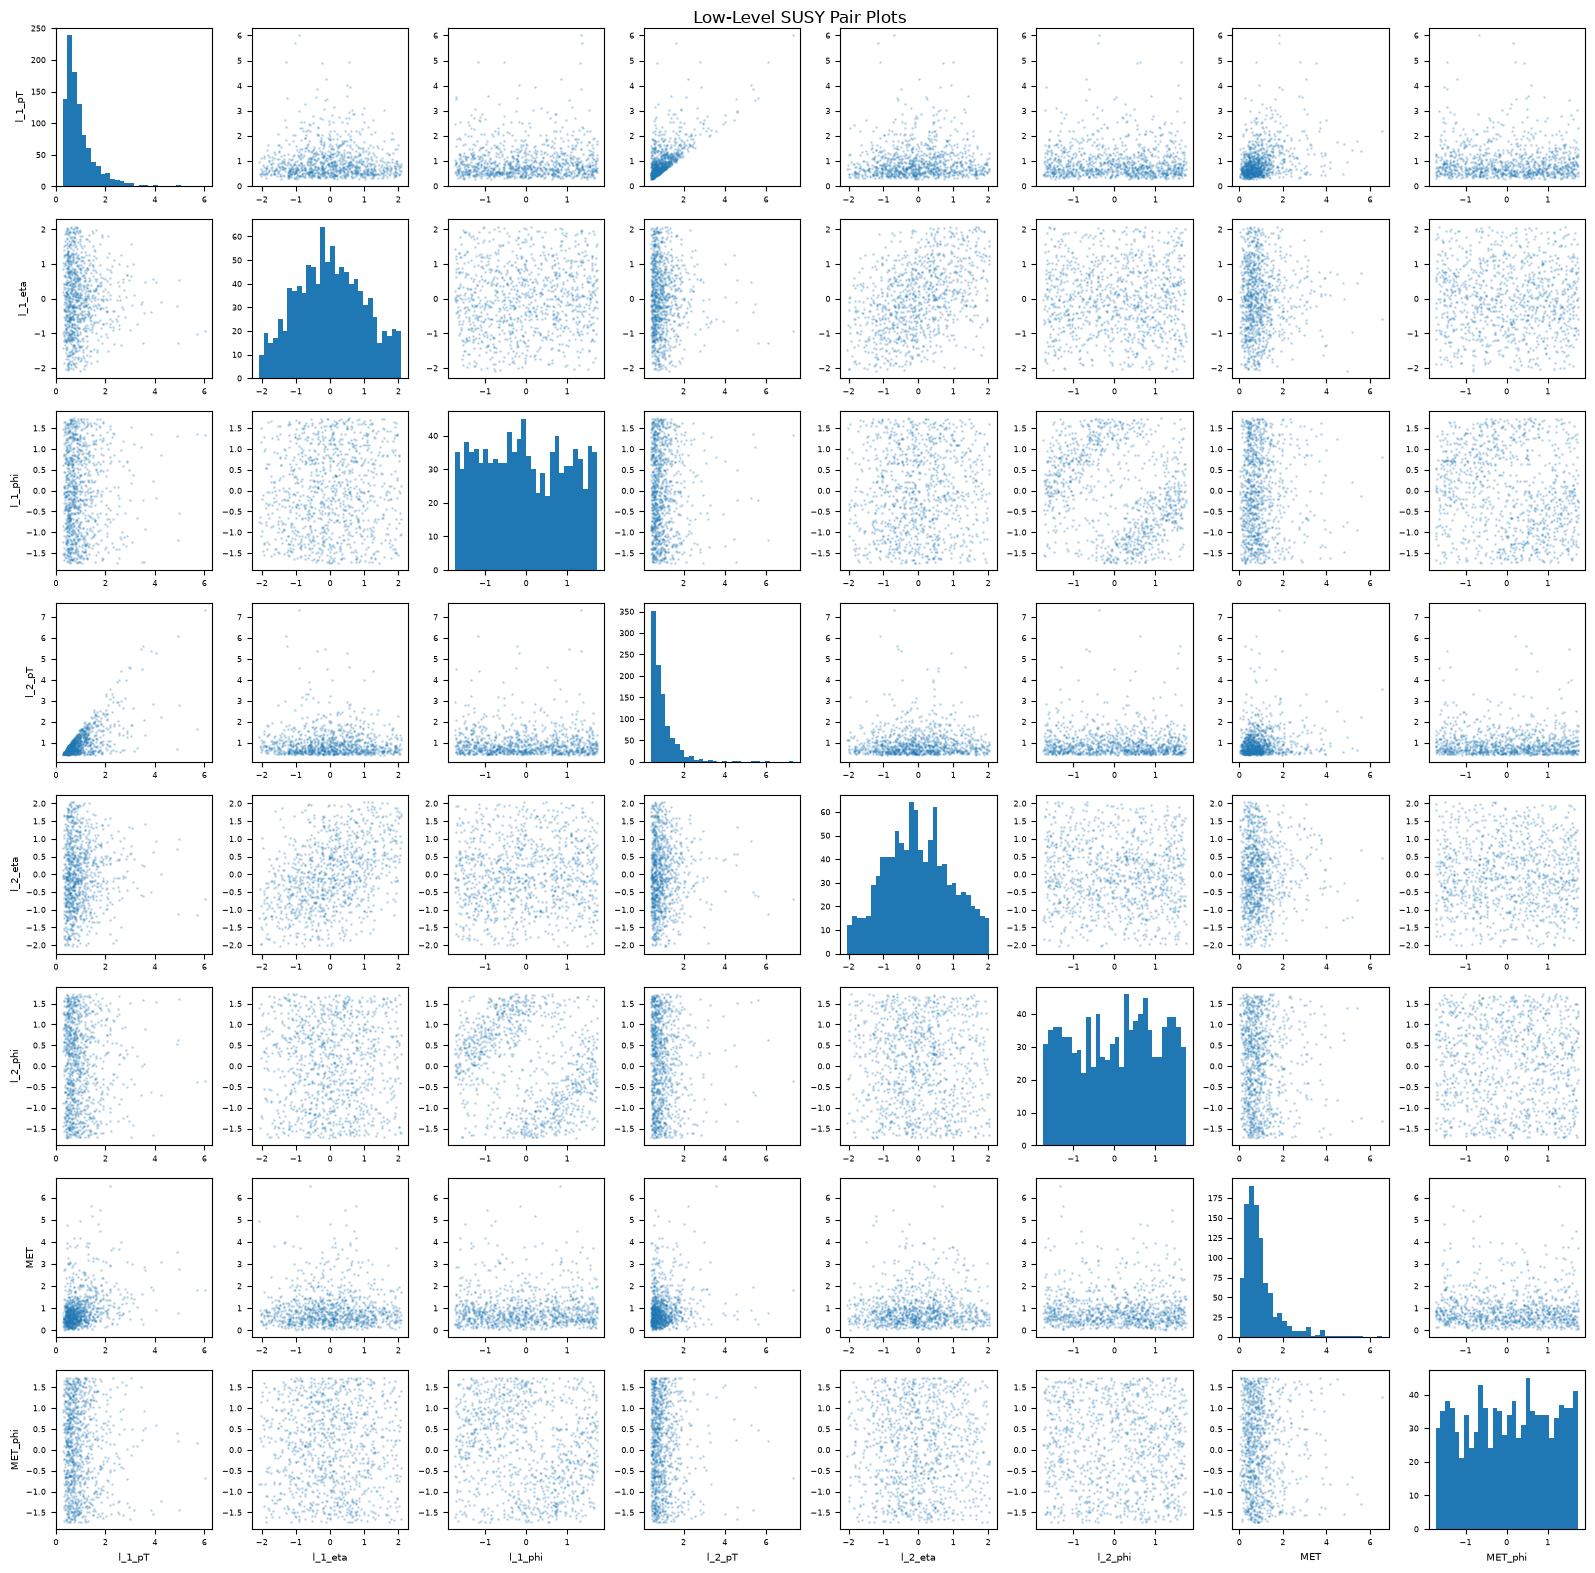

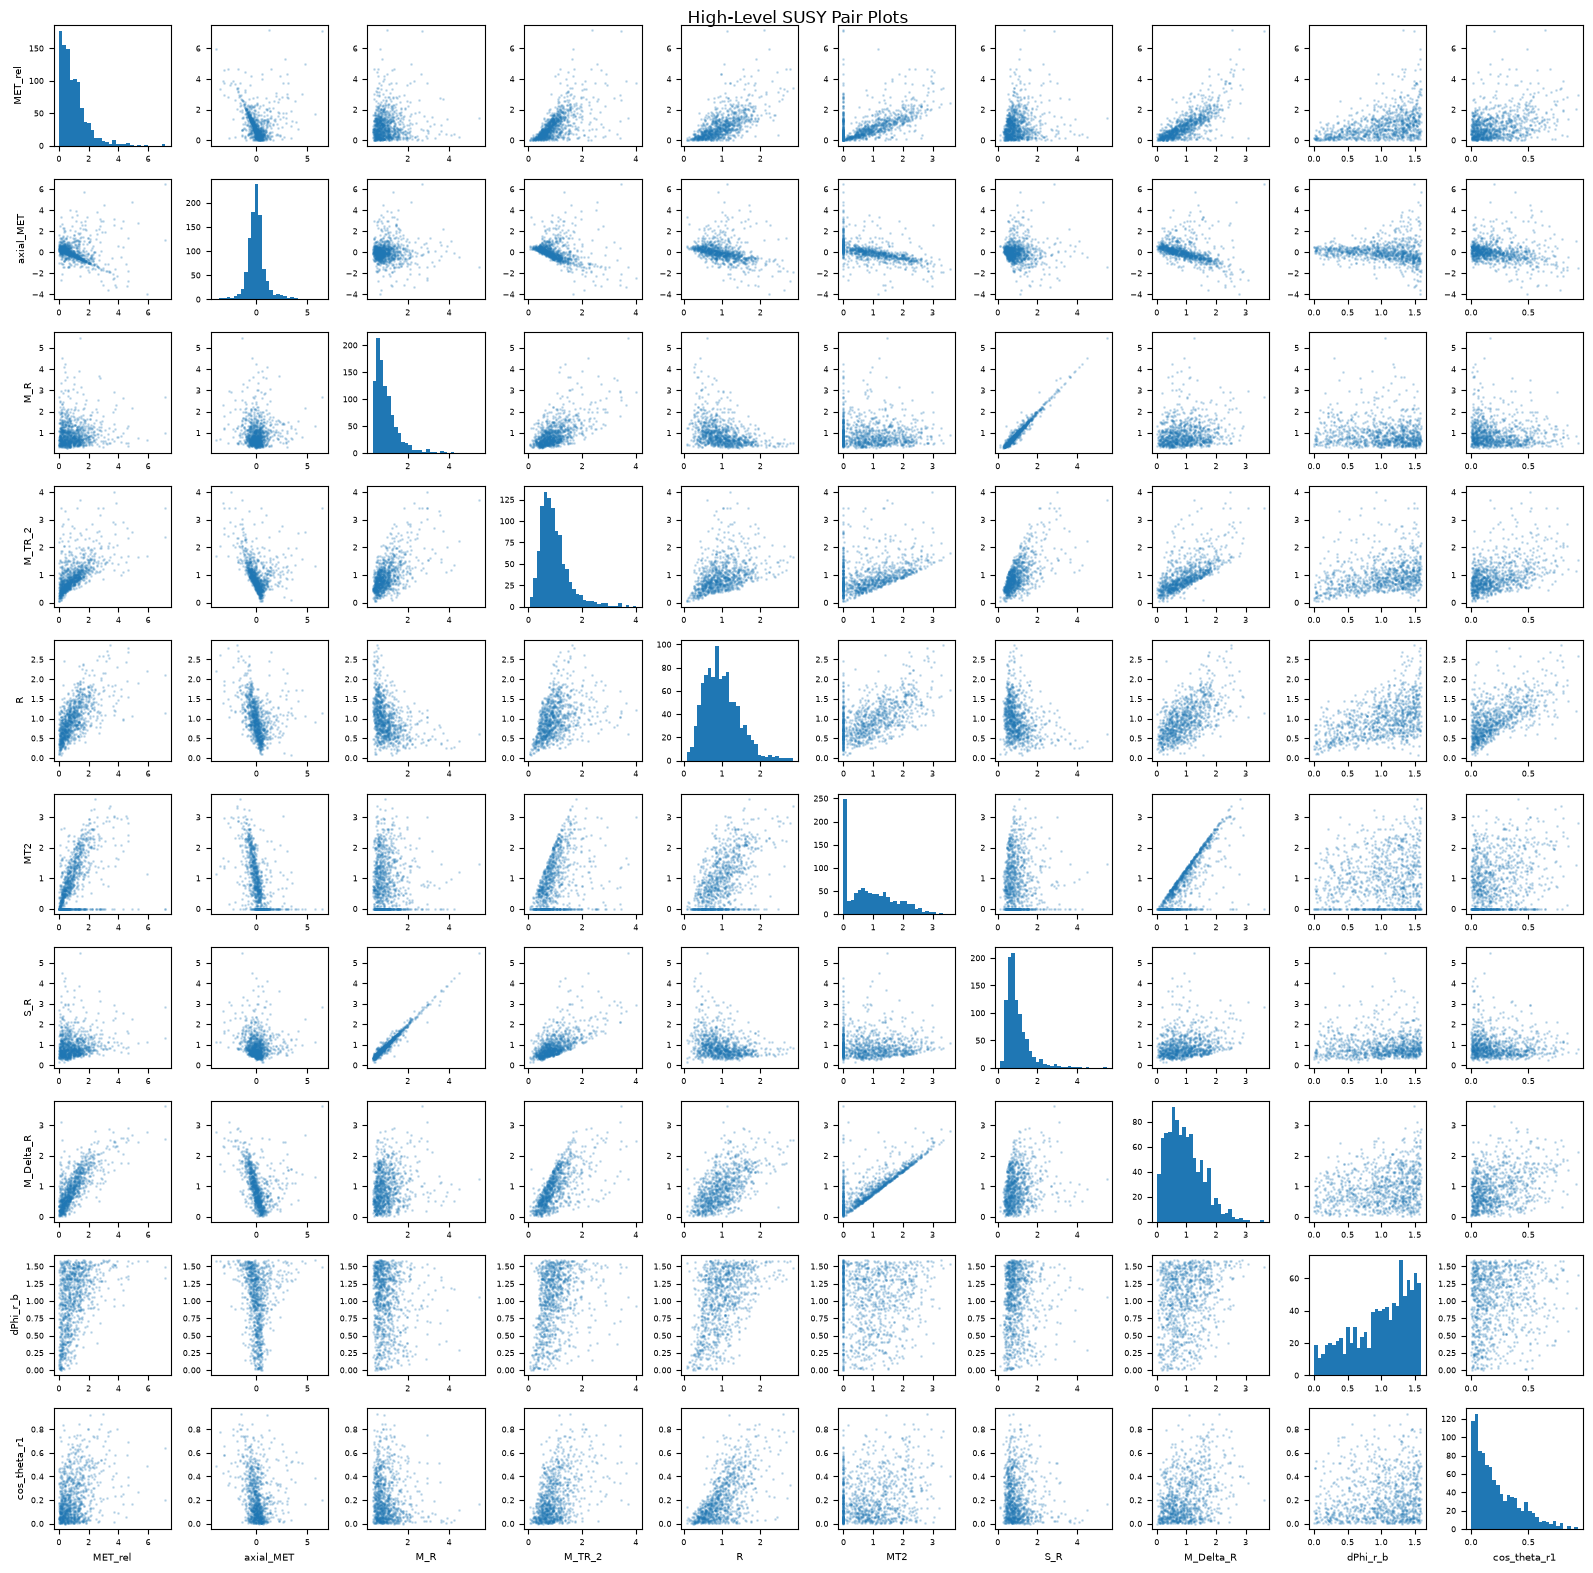

In [20]:
#PART A
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
VarNames = [
    "signal", "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi", "MET_rel", "axial_MET",
    "M_R", "M_TR_2", "R", "MT2", "S_R",
    "M_Delta_R", "dPhi_r_b", "cos_theta_r1"
]

df = pd.read_csv("SUSY-small.csv", header=None, names=VarNames)

RawNames = VarNames[1:9]
FeatureNames = VarNames[9:]
def pair_plots(data, columns, title):
    n = len(columns)
    fig, axes = plt.subplots(n, n, figsize=(16, 16))

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]

            if i == j:
                ax.hist(data[columns[i]], bins=30)
            else:
                ax.scatter(
                    data[columns[j]],
                    data[columns[i]],
                    s=1,
                    alpha=0.2
                )

            if i == n - 1:
                ax.set_xlabel(columns[j], fontsize=7)

            if j == 0:
                ax.set_ylabel(columns[i], fontsize=7)

            ax.tick_params(labelsize=6)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
sample = df.sample(n=1000, random_state=42)

pair_plots(sample, RawNames, "Low-Level SUSY Pair Plots")

pair_plots(sample, FeatureNames, "High-Level SUSY Pair Plots")

In [ ]:
#PART C
from sklearn.metrics import roc_auc_score
import pandas as pd

results = []

for col in RawNames + FeatureNames:
    auc = roc_auc_score(df["signal"], df[col])
    results.append({
        "Observable": col,
        "Separation Score": max(auc, 1 - auc)
    })

ranking = pd.DataFrame(results)
ranking = ranking.sort_values(
    "Separation Score", ascending=False
)

print(ranking.to_string(index=False))
print("\nTop 3 observables:")
print(ranking.head(3))
#The three best individual observables for separating signal from background are **MET (0.7710), l_1_pT (0.7636), and M_TR_2 (0.7582).
#These observables have the highest ROC-AUC-based separation scores. Scores closer to 1 indicate better discrimination, while 0.5 indicates 
#little or no discrimination. Therefore, these three variables provide the strongest individual separation in our SUSY sample.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [3]:
%pip install tabulate

import numpy as np
import pandas as pd
from tabulate import tabulate
from IPython.display import display, HTML

VarNames = [
    "signal", "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi", "MET_rel", "axial_MET",
    "M_R", "M_TR_2", "R", "MT2", "S_R",
    "M_Delta_R", "dPhi_r_b", "cos_theta_r1"
]

RawNames = VarNames[1:9]
FeatureNames = VarNames[9:]
AllObservables = VarNames[1:]

df = pd.read_csv("SUSY-small.csv", header=None, names=VarNames)

def show_matrices(data, columns, title):
    values = data[columns].to_numpy()


    covariance = np.cov(values, rowvar=False)
    correlation = np.corrcoef(values, rowvar=False)

    for name, matrix in [
        ("Covariance Matrix", covariance),
        ("Correlation Matrix", correlation)
    ]:
        print(f"\n{title} - {name}")

        table = [
            [column] + list(matrix[i])
            for i, column in enumerate(columns)
        ]

        display(HTML(tabulate(
            table,
            headers=["Variable"] + columns,
            tablefmt="html",
            floatfmt=".3f"
        )))

    return covariance, correlation

cov_all, corr_all = show_matrices(
    df, AllObservables, "All Observables"
)

cov_low, corr_low = show_matrices(
    df, RawNames, "Low-Level Observables"
)

cov_high, corr_high = show_matrices(
    df, FeatureNames, "High-Level Observables"
)



Note: you may need to restart the kernel to use updated packages.

All Observables - Covariance Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000,0.000,0.305,-0.000,0.001,0.228,-0.001,0.098,-0.010,0.364,0.287,-0.060,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0.000,1.004,-0.001,-0.000,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0.000,0.000,-0.001,-0.001,-0.001,0.000
l_1_phi,0.000,-0.001,1.004,0.001,0.000,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0.000,0.001,0.001,0.001,0.001,0.000
l_2_pT,0.305,-0.000,0.001,0.425,-0.001,0.000,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0.000,0.408,0.000,-0.001,1.006,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.000,0.001,-0.001,0.001,-0.000,0.000
l_2_phi,0.001,-0.001,-0.267,0.000,0.000,1.004,-0.000,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0.000,0.000
MET,0.228,-0.002,0.001,0.079,0.000,-0.000,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0.000,-0.035,-0.003,1.003,-0.005,-0.000,-0.001,-0.001,-0.000,0.000,-0.002,-0.001,-0.002,0.000
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.010,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0.000,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054



All Observables - Correlation Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001,0.160,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0.000,-0.001,-0.002,-0.002,0.002
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0.000,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002,-0.001,0.078,0.797,0.430,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0.000
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003,0.704,0.176,0.264,0.720,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000,-0.005,-0.000,-0.002,-0.002,-0.000,0.000,-0.003,-0.001,-0.004,0.001
MET_rel,0.160,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0.000,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272



Low-Level Observables - Covariance Matrix


...

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000



High-Level Observables - Covariance Matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.210,-0.113,-0.037,0.380,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.210,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.380,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.010
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.190,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.010,0.039,0.009,0.039



High-Level Observables - Correlation Matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1.000,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1.000,0.380,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.380,1.000,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1.000,-0.021,0.809,0.056,0.264
S_R,0.150,-0.067,0.981,0.635,-0.287,-0.021,1.000,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1.000,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1.000,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1.000


In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [4]:

# Exercise 5.1(a): Selection criteria

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

RawNames = [
    "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi"
]

FeatureNames = [
    "MET_rel", "axial_MET", "M_R", "M_TR_2",
    "R", "MT2", "S_R", "M_Delta_R",
    "dPhi_r_b", "cos_theta_r1"
]

df = pd.read_csv(
    "SUSY-small.csv",
    header=None,
    names=["signal"] + RawNames + FeatureNames
)

results = []

for col in RawNames + FeatureNames:
    auc = roc_auc_score(df["signal"], df[col])

    if auc >= 0.5:
        criterion = f"{col} > x_c"
    else:
        criterion = f"{col} < x_c"

    results.append({
        "Observable": col,
        "ROC-AUC": round(auc, 4),
        "Suggested Criterion": criterion
    })

selection_table = pd.DataFrame(results)

print(selection_table.to_string(index=False))


  Observable  ROC-AUC Suggested Criterion
      l_1_pT   0.7636        l_1_pT > x_c
     l_1_eta   0.5002       l_1_eta > x_c
     l_1_phi   0.5002       l_1_phi > x_c
      l_2_pT   0.6231        l_2_pT > x_c
     l_2_eta   0.5009       l_2_eta > x_c
     l_2_phi   0.5002       l_2_phi > x_c
         MET   0.7710           MET > x_c
     MET_phi   0.4997       MET_phi < x_c
     MET_rel   0.6301       MET_rel > x_c
   axial_MET   0.4982     axial_MET < x_c
         M_R   0.7047           M_R > x_c
      M_TR_2   0.7582        M_TR_2 > x_c
           R   0.5609             R > x_c
         MT2   0.5177           MT2 > x_c
         S_R   0.6995           S_R > x_c
   M_Delta_R   0.6412     M_Delta_R > x_c
    dPhi_r_b   0.5174      dPhi_r_b > x_c
cos_theta_r1   0.6448  cos_theta_r1 > x_c


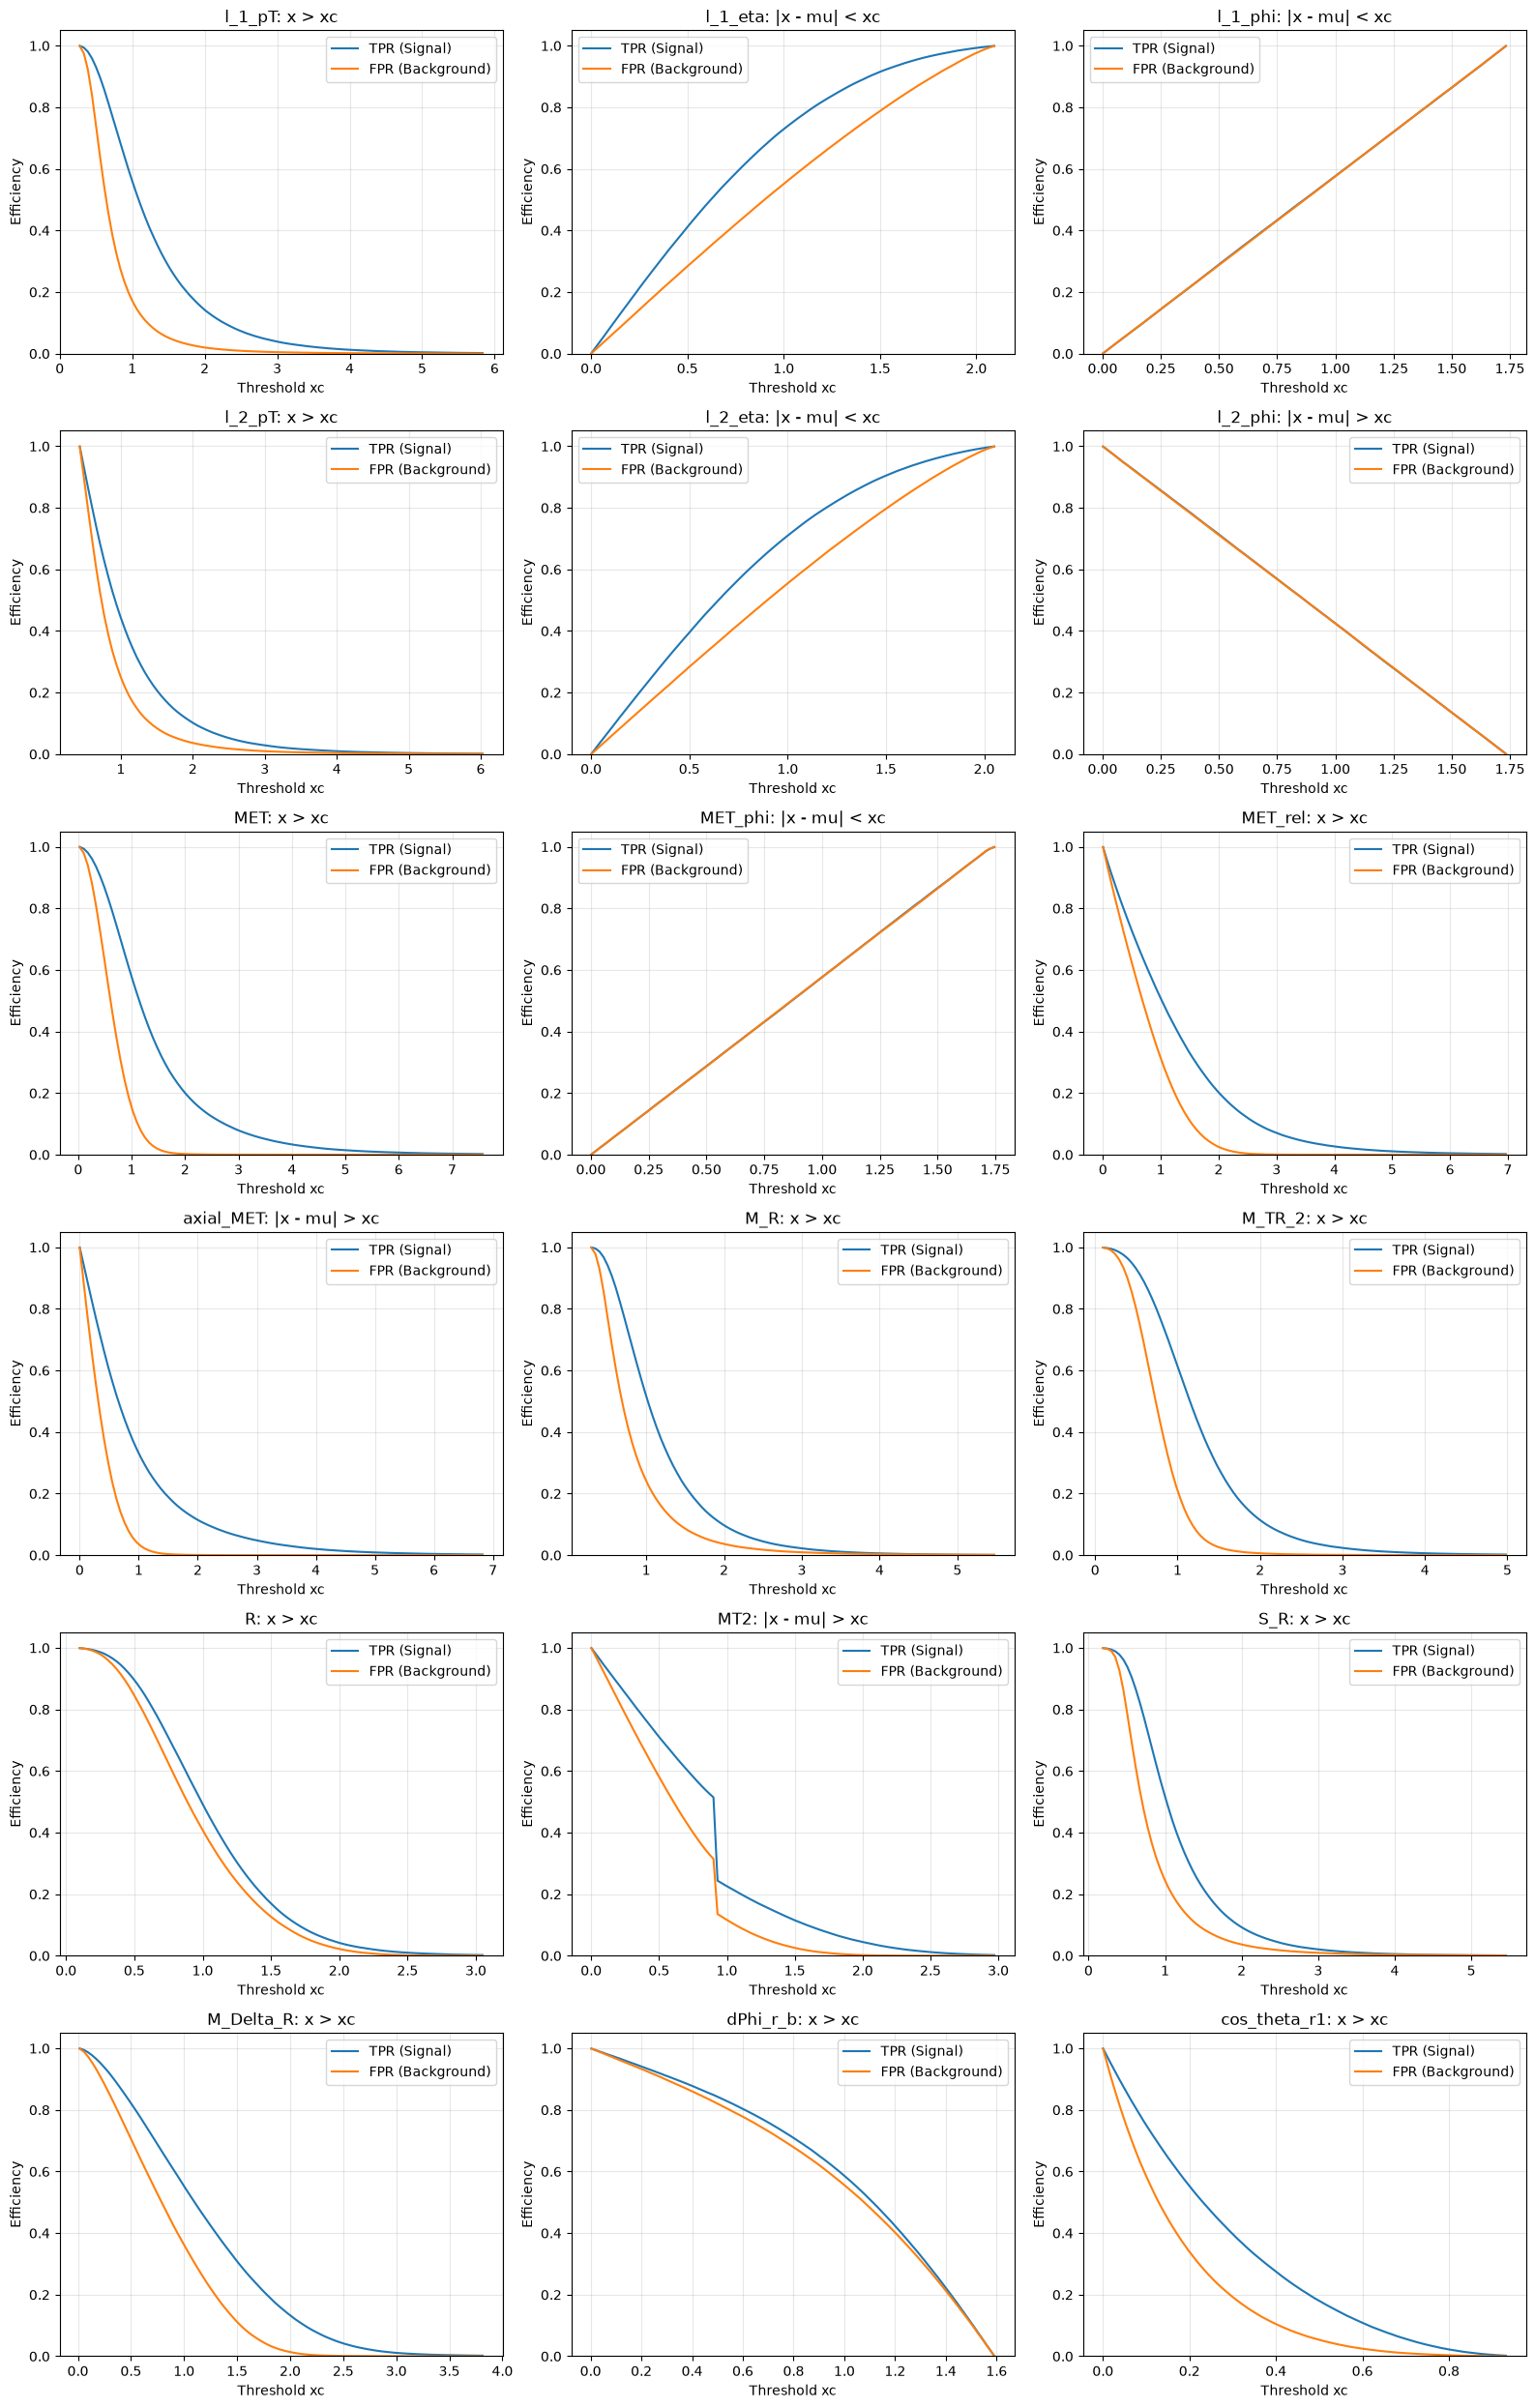

In [6]:
#5.2 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RawNames = [
    "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi"
]

FeatureNames = [
    "MET_rel", "axial_MET", "M_R", "M_TR_2",
    "R", "MT2", "S_R", "M_Delta_R",
    "dPhi_r_b", "cos_theta_r1"
]

df = pd.read_csv(
    "SUSY-small.csv",
    header=None,
    names=["signal"] + RawNames + FeatureNames
)

criteria = dict(zip(
    selection_results["Observable"],
    selection_results["Best Criterion"]
))

mu_values = dict(zip(
    selection_results["Observable"],
    selection_results["mu"]
))

signal = df["signal"].to_numpy() == 1
background = ~signal

fig, axes = plt.subplots(6, 3, figsize=(16, 25))

for ax, col in zip(axes.ravel(), RawNames + FeatureNames):
    x = df[col].to_numpy()
    criterion = criteria[col]
    mu = mu_values[col]

    if criterion == "x > xc":
        values = x
        direction = ">"
    elif criterion == "x < xc":
        values = x
        direction = "<"
    elif criterion == "|x - mu| > xc":
        values = np.abs(x - mu)
        direction = ">"
    else:
        values = np.abs(x - mu)
        direction = "<"

    thresholds = np.linspace(
        np.percentile(values, 0.1),
        np.percentile(values, 99.9),
        100
    )

    signal_values = np.sort(values[signal])
    background_values = np.sort(values[background])

    if direction == ">":
        tpr = 1 - np.searchsorted(
            signal_values, thresholds, side="right"
        ) / len(signal_values)

        fpr = 1 - np.searchsorted(
            background_values, thresholds, side="right"
        ) / len(background_values)
    else:
        tpr = np.searchsorted(
            signal_values, thresholds, side="left"
        ) / len(signal_values)

        fpr = np.searchsorted(
            background_values, thresholds, side="left"
        ) / len(background_values)

    ax.plot(thresholds, tpr, label="TPR (Signal)")
    ax.plot(thresholds, fpr, label="FPR (Background)")

    ax.set_title(f"{col}: {criterion}")
    ax.set_xlabel("Threshold xc")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


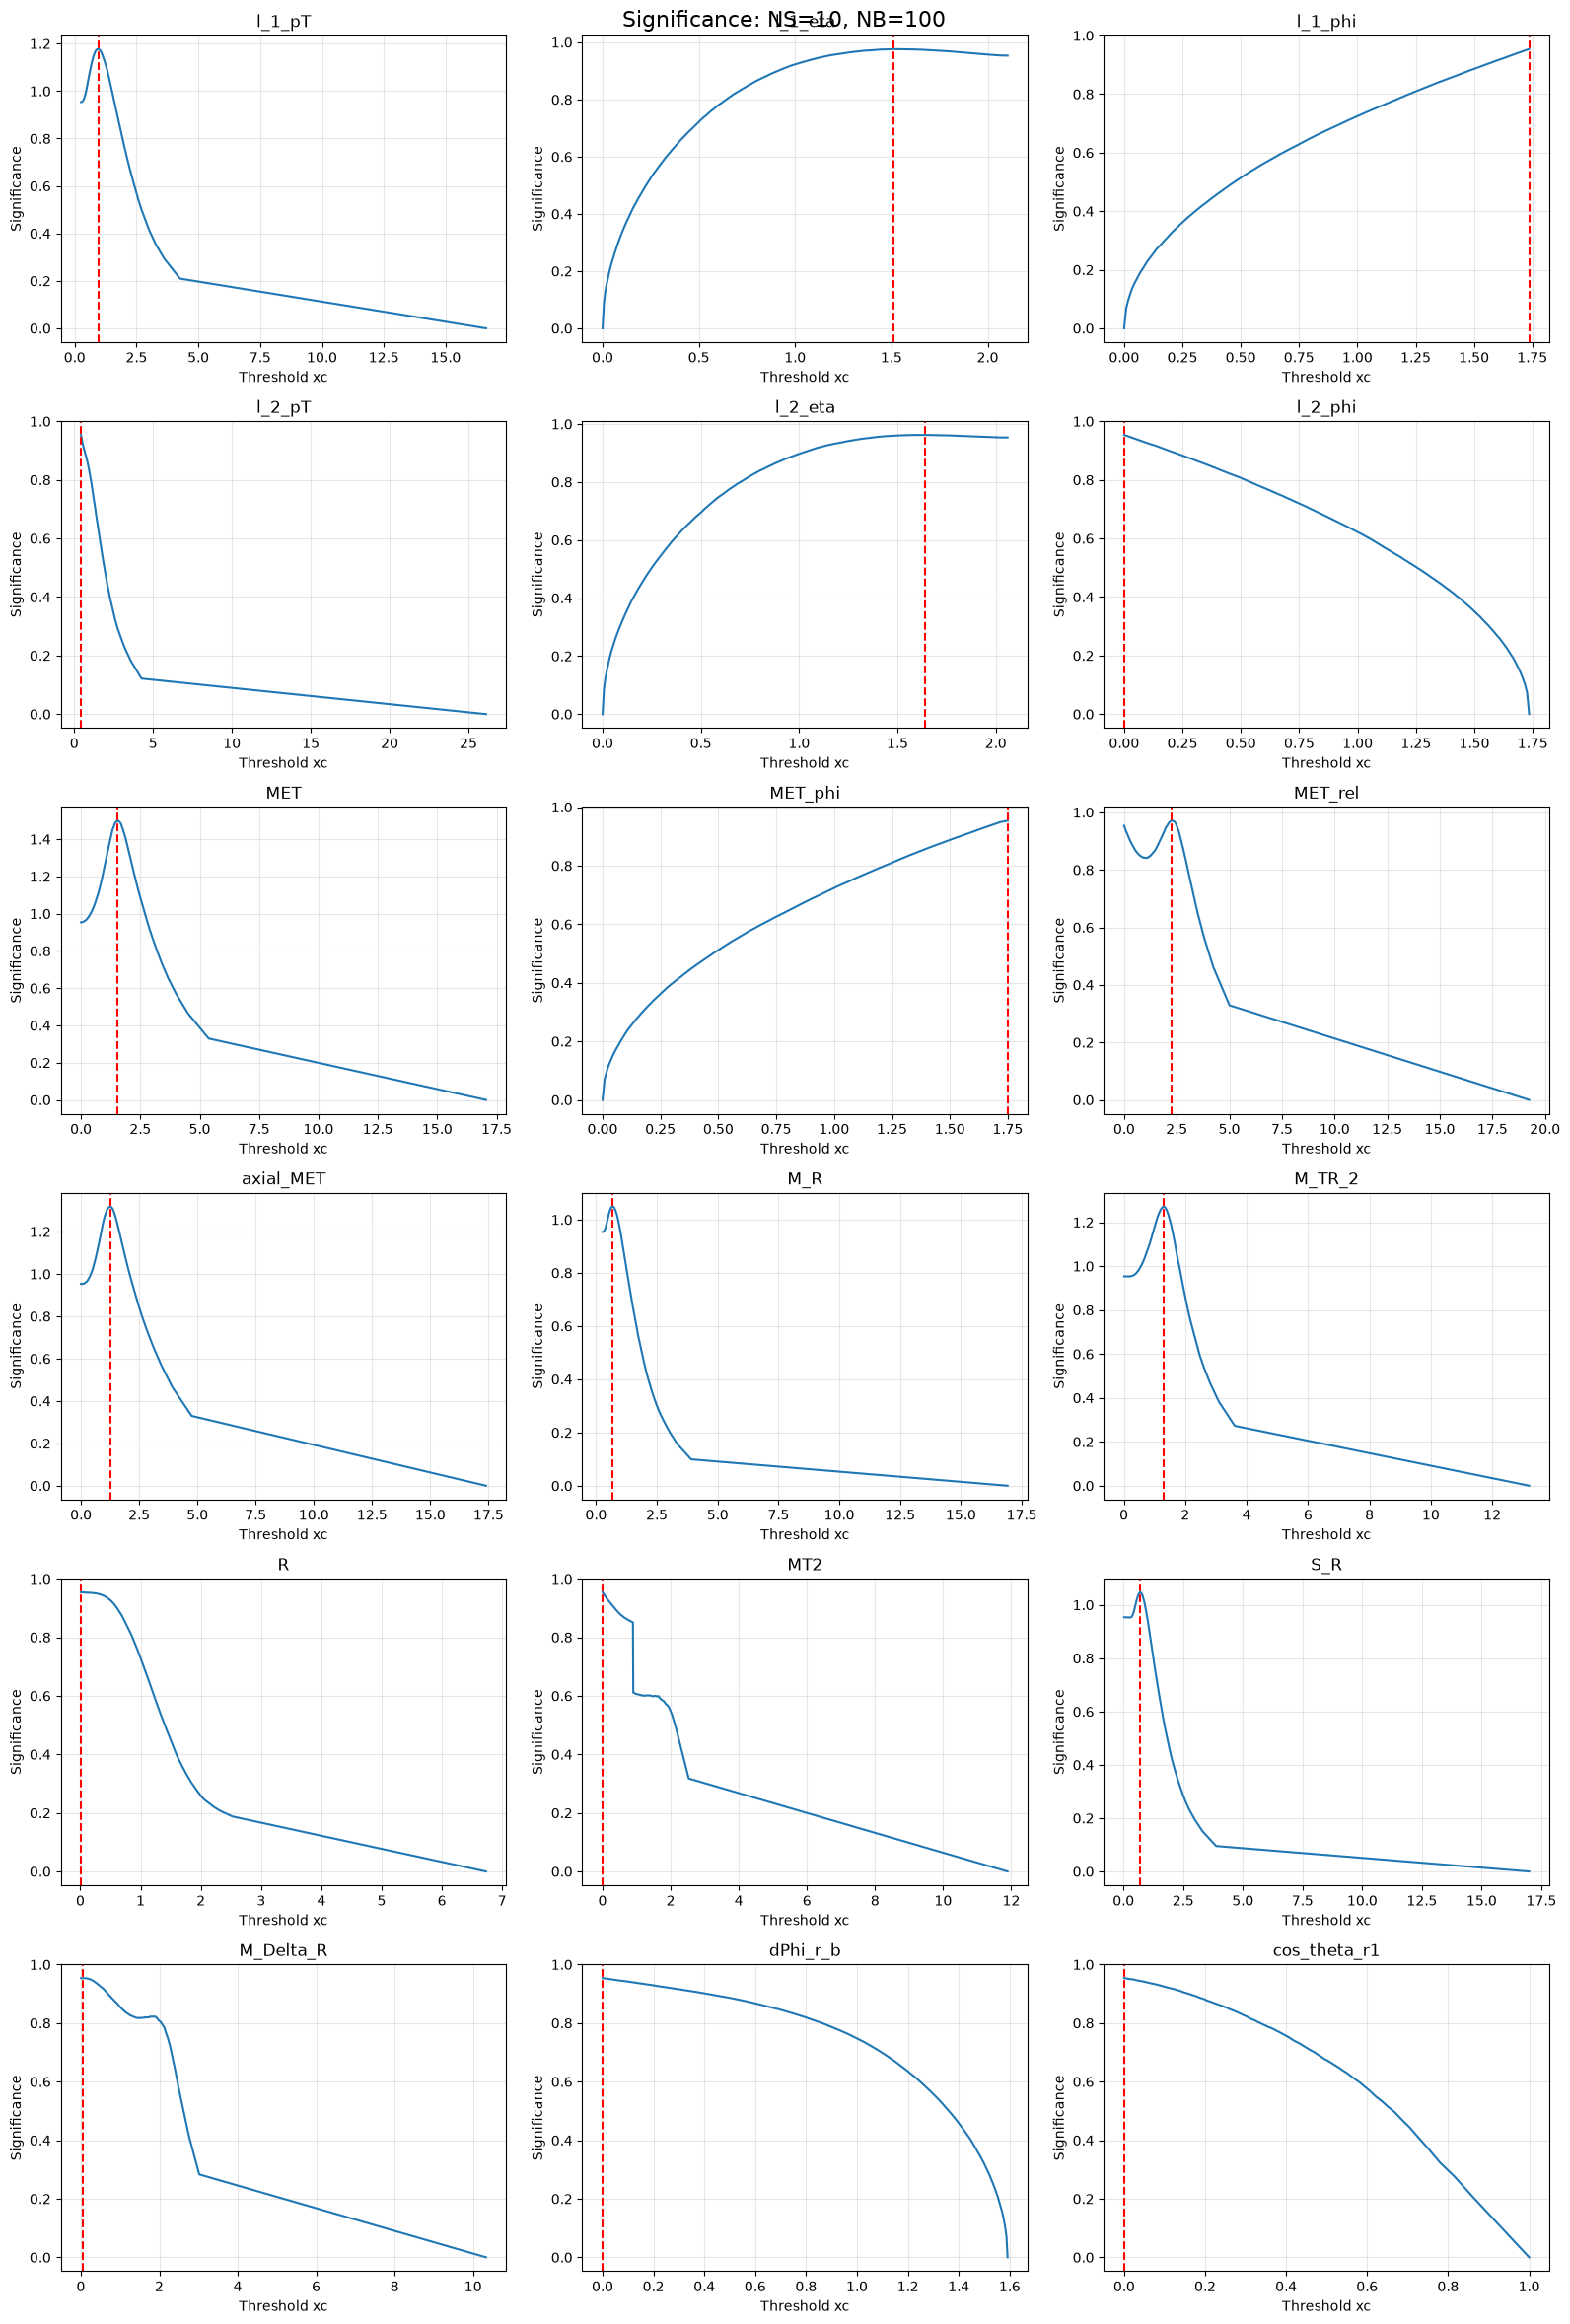

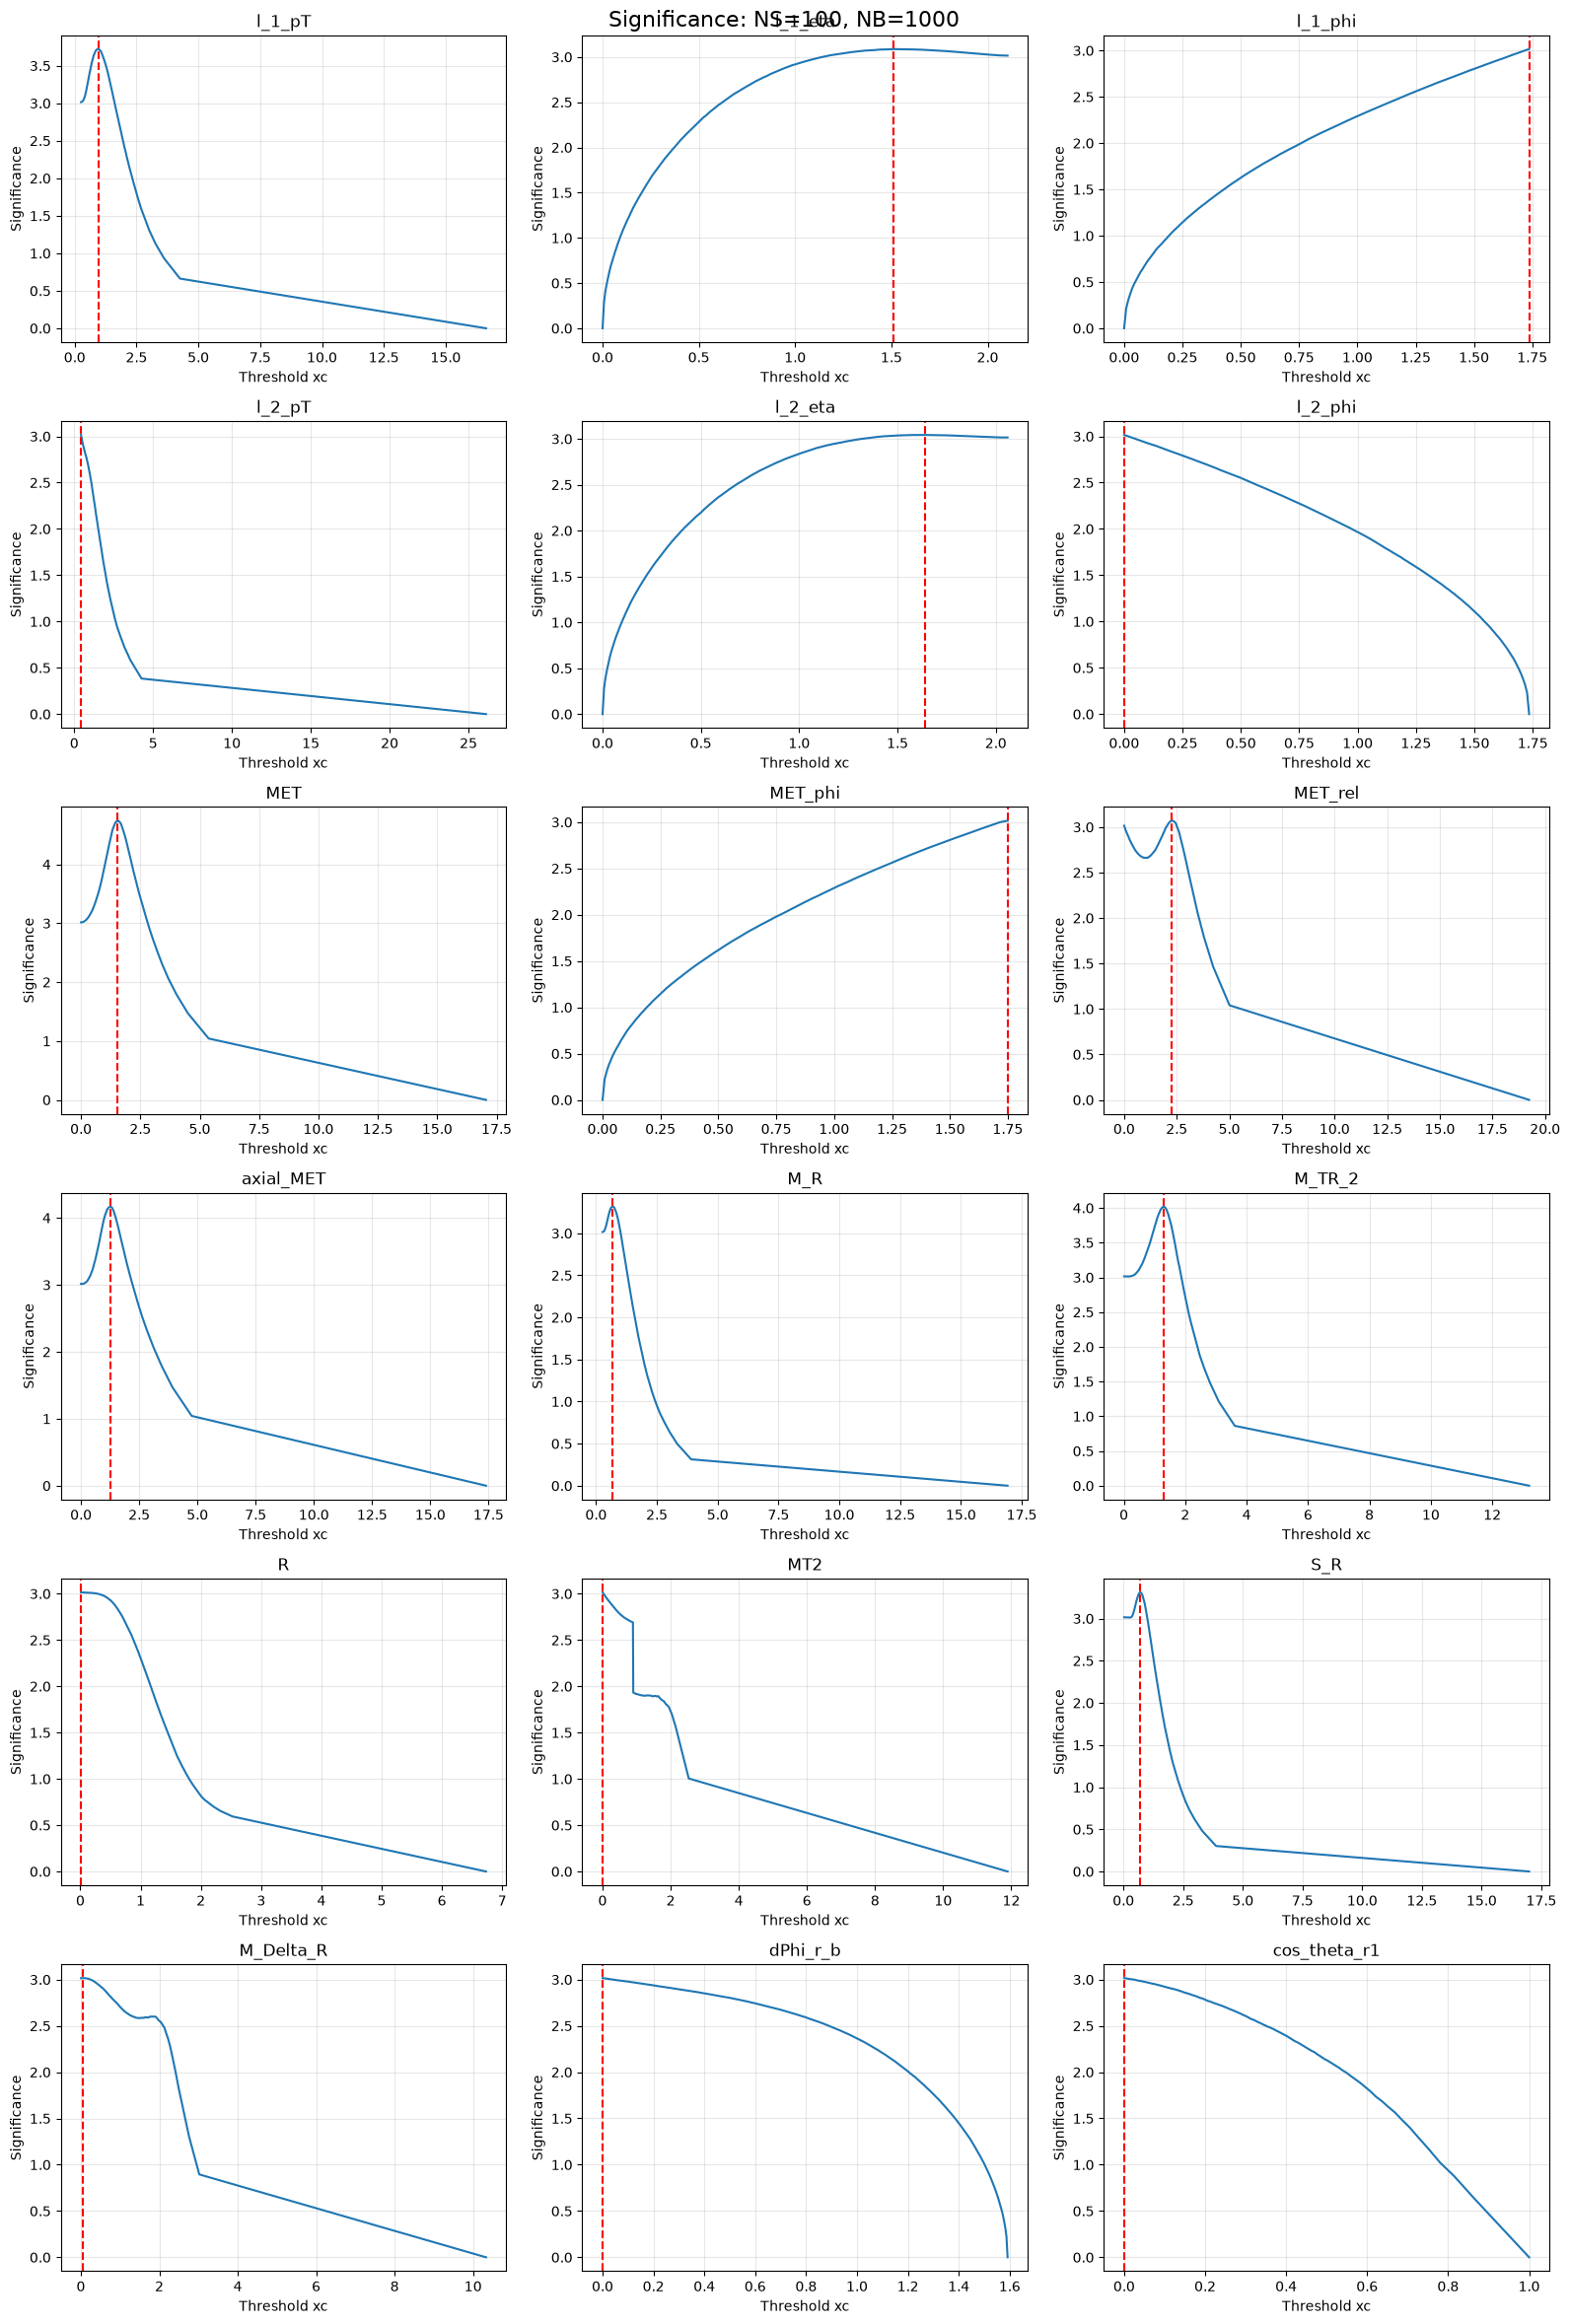

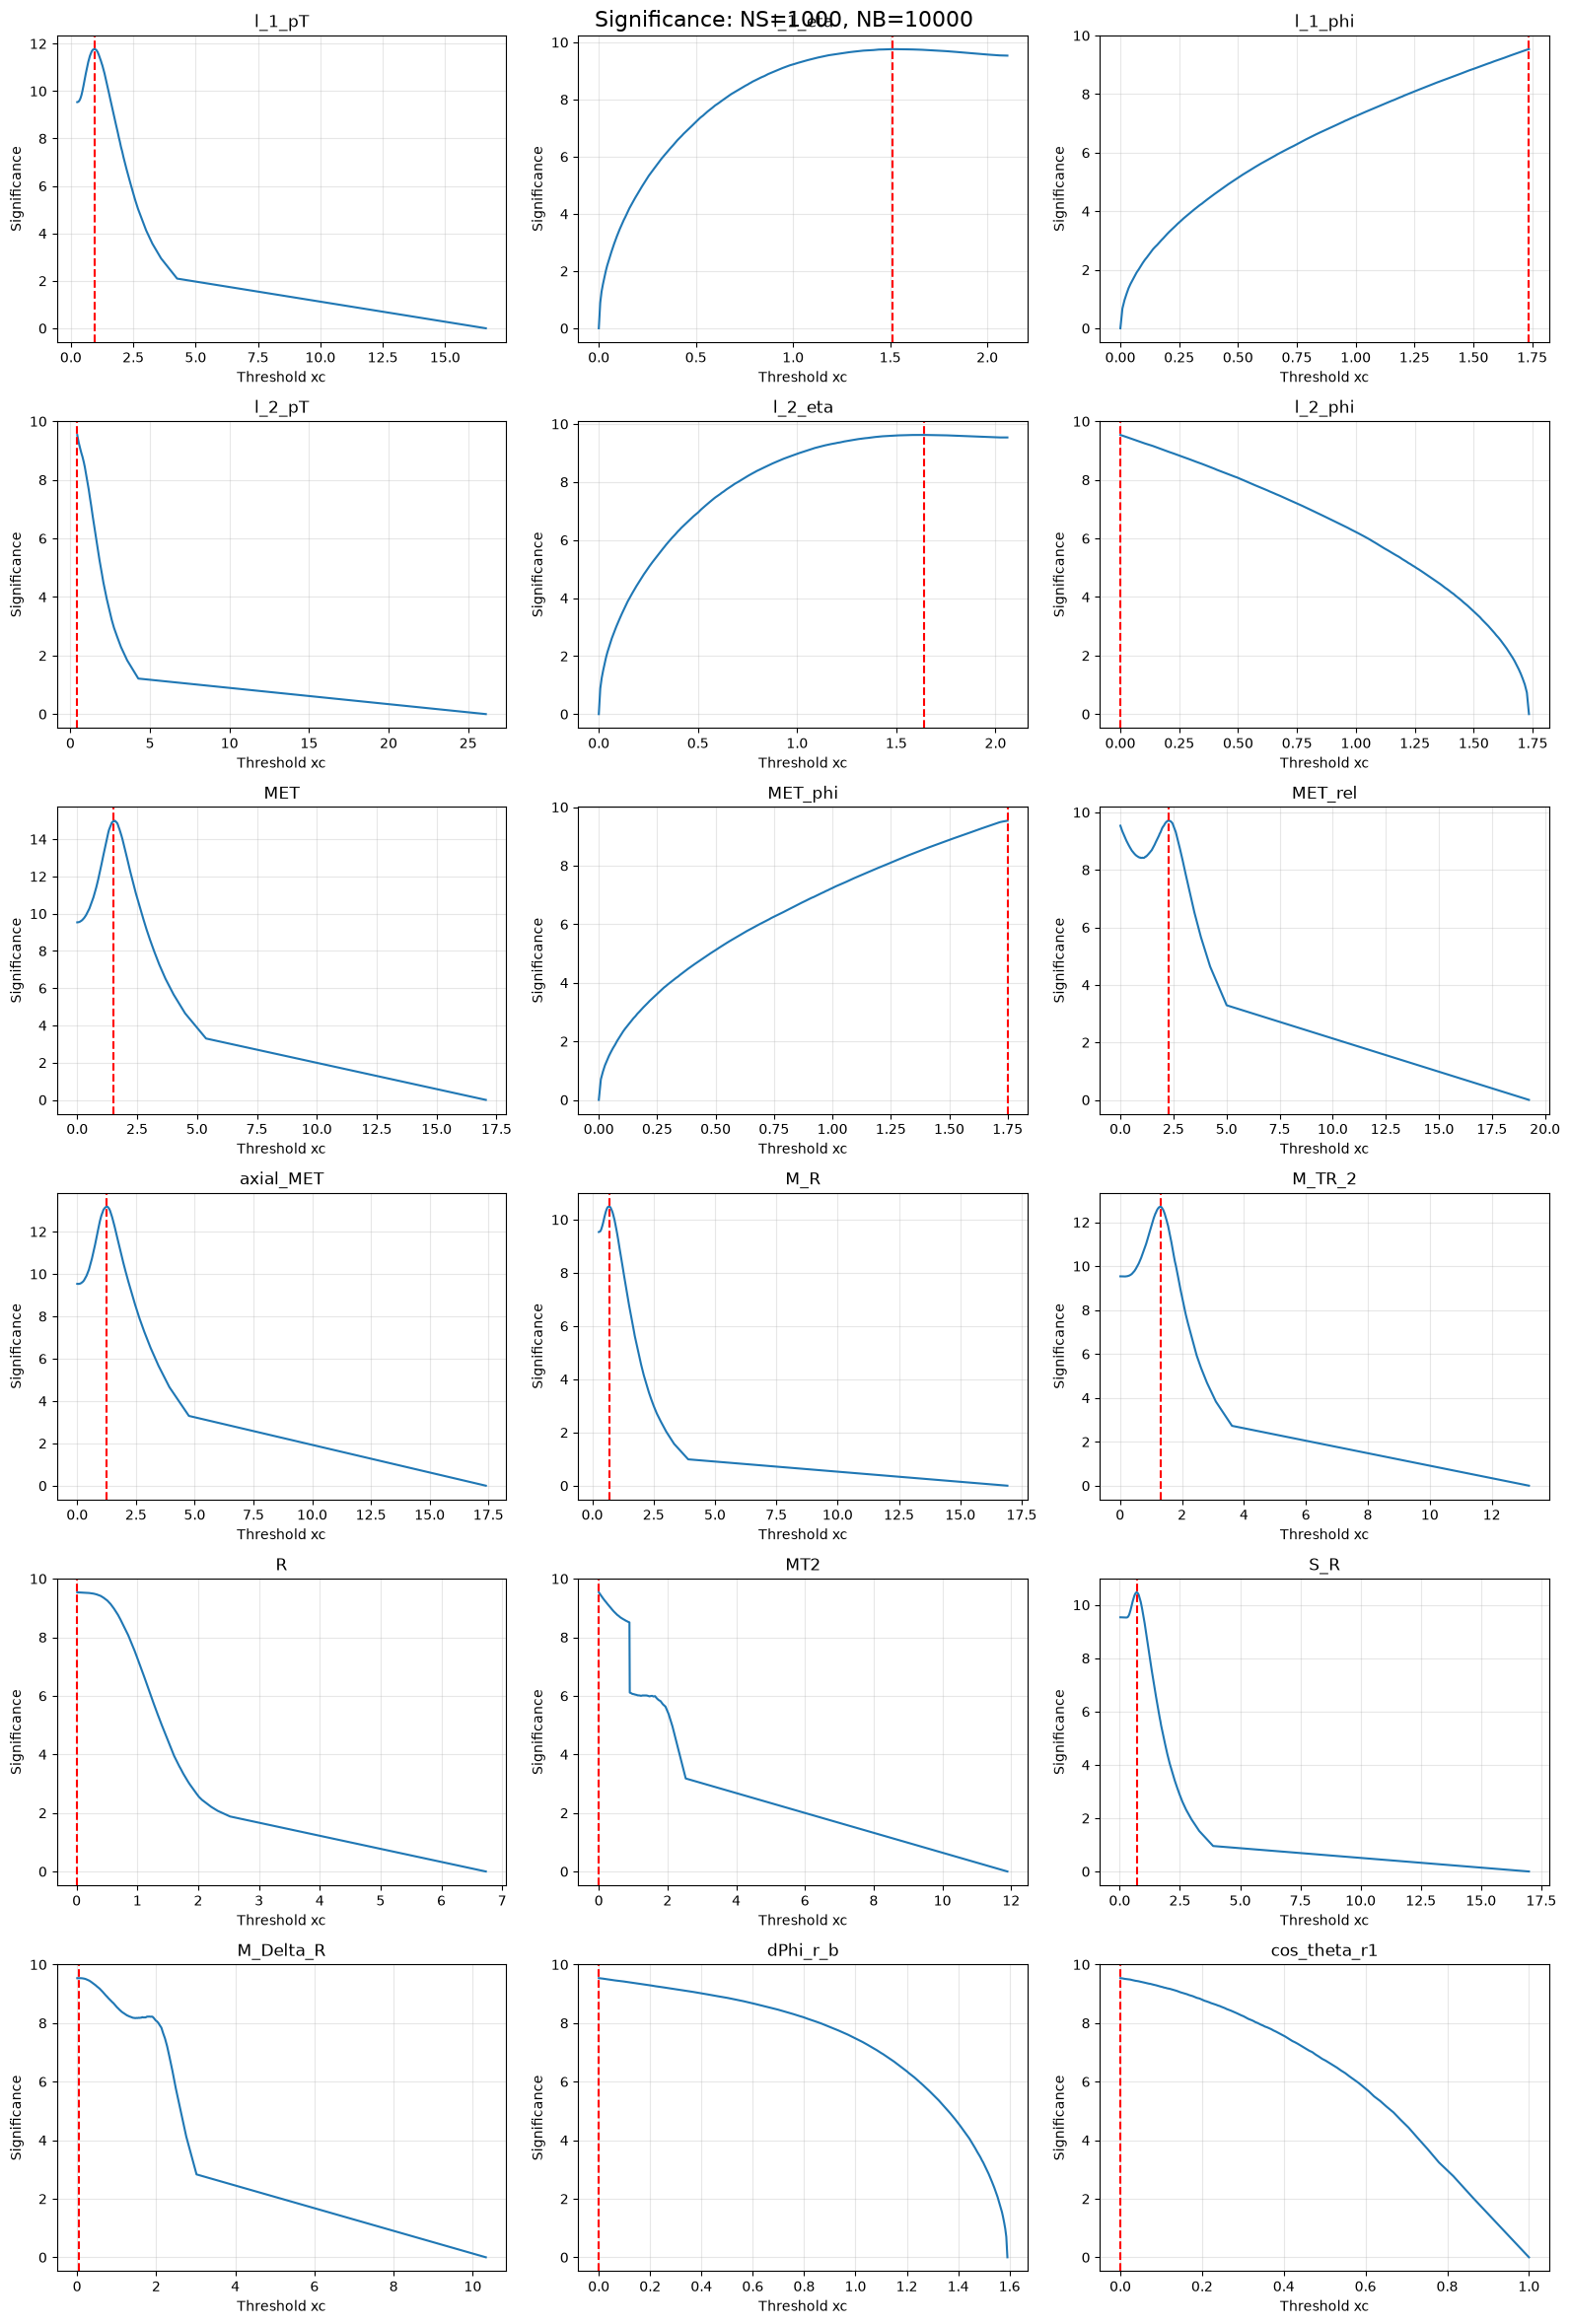

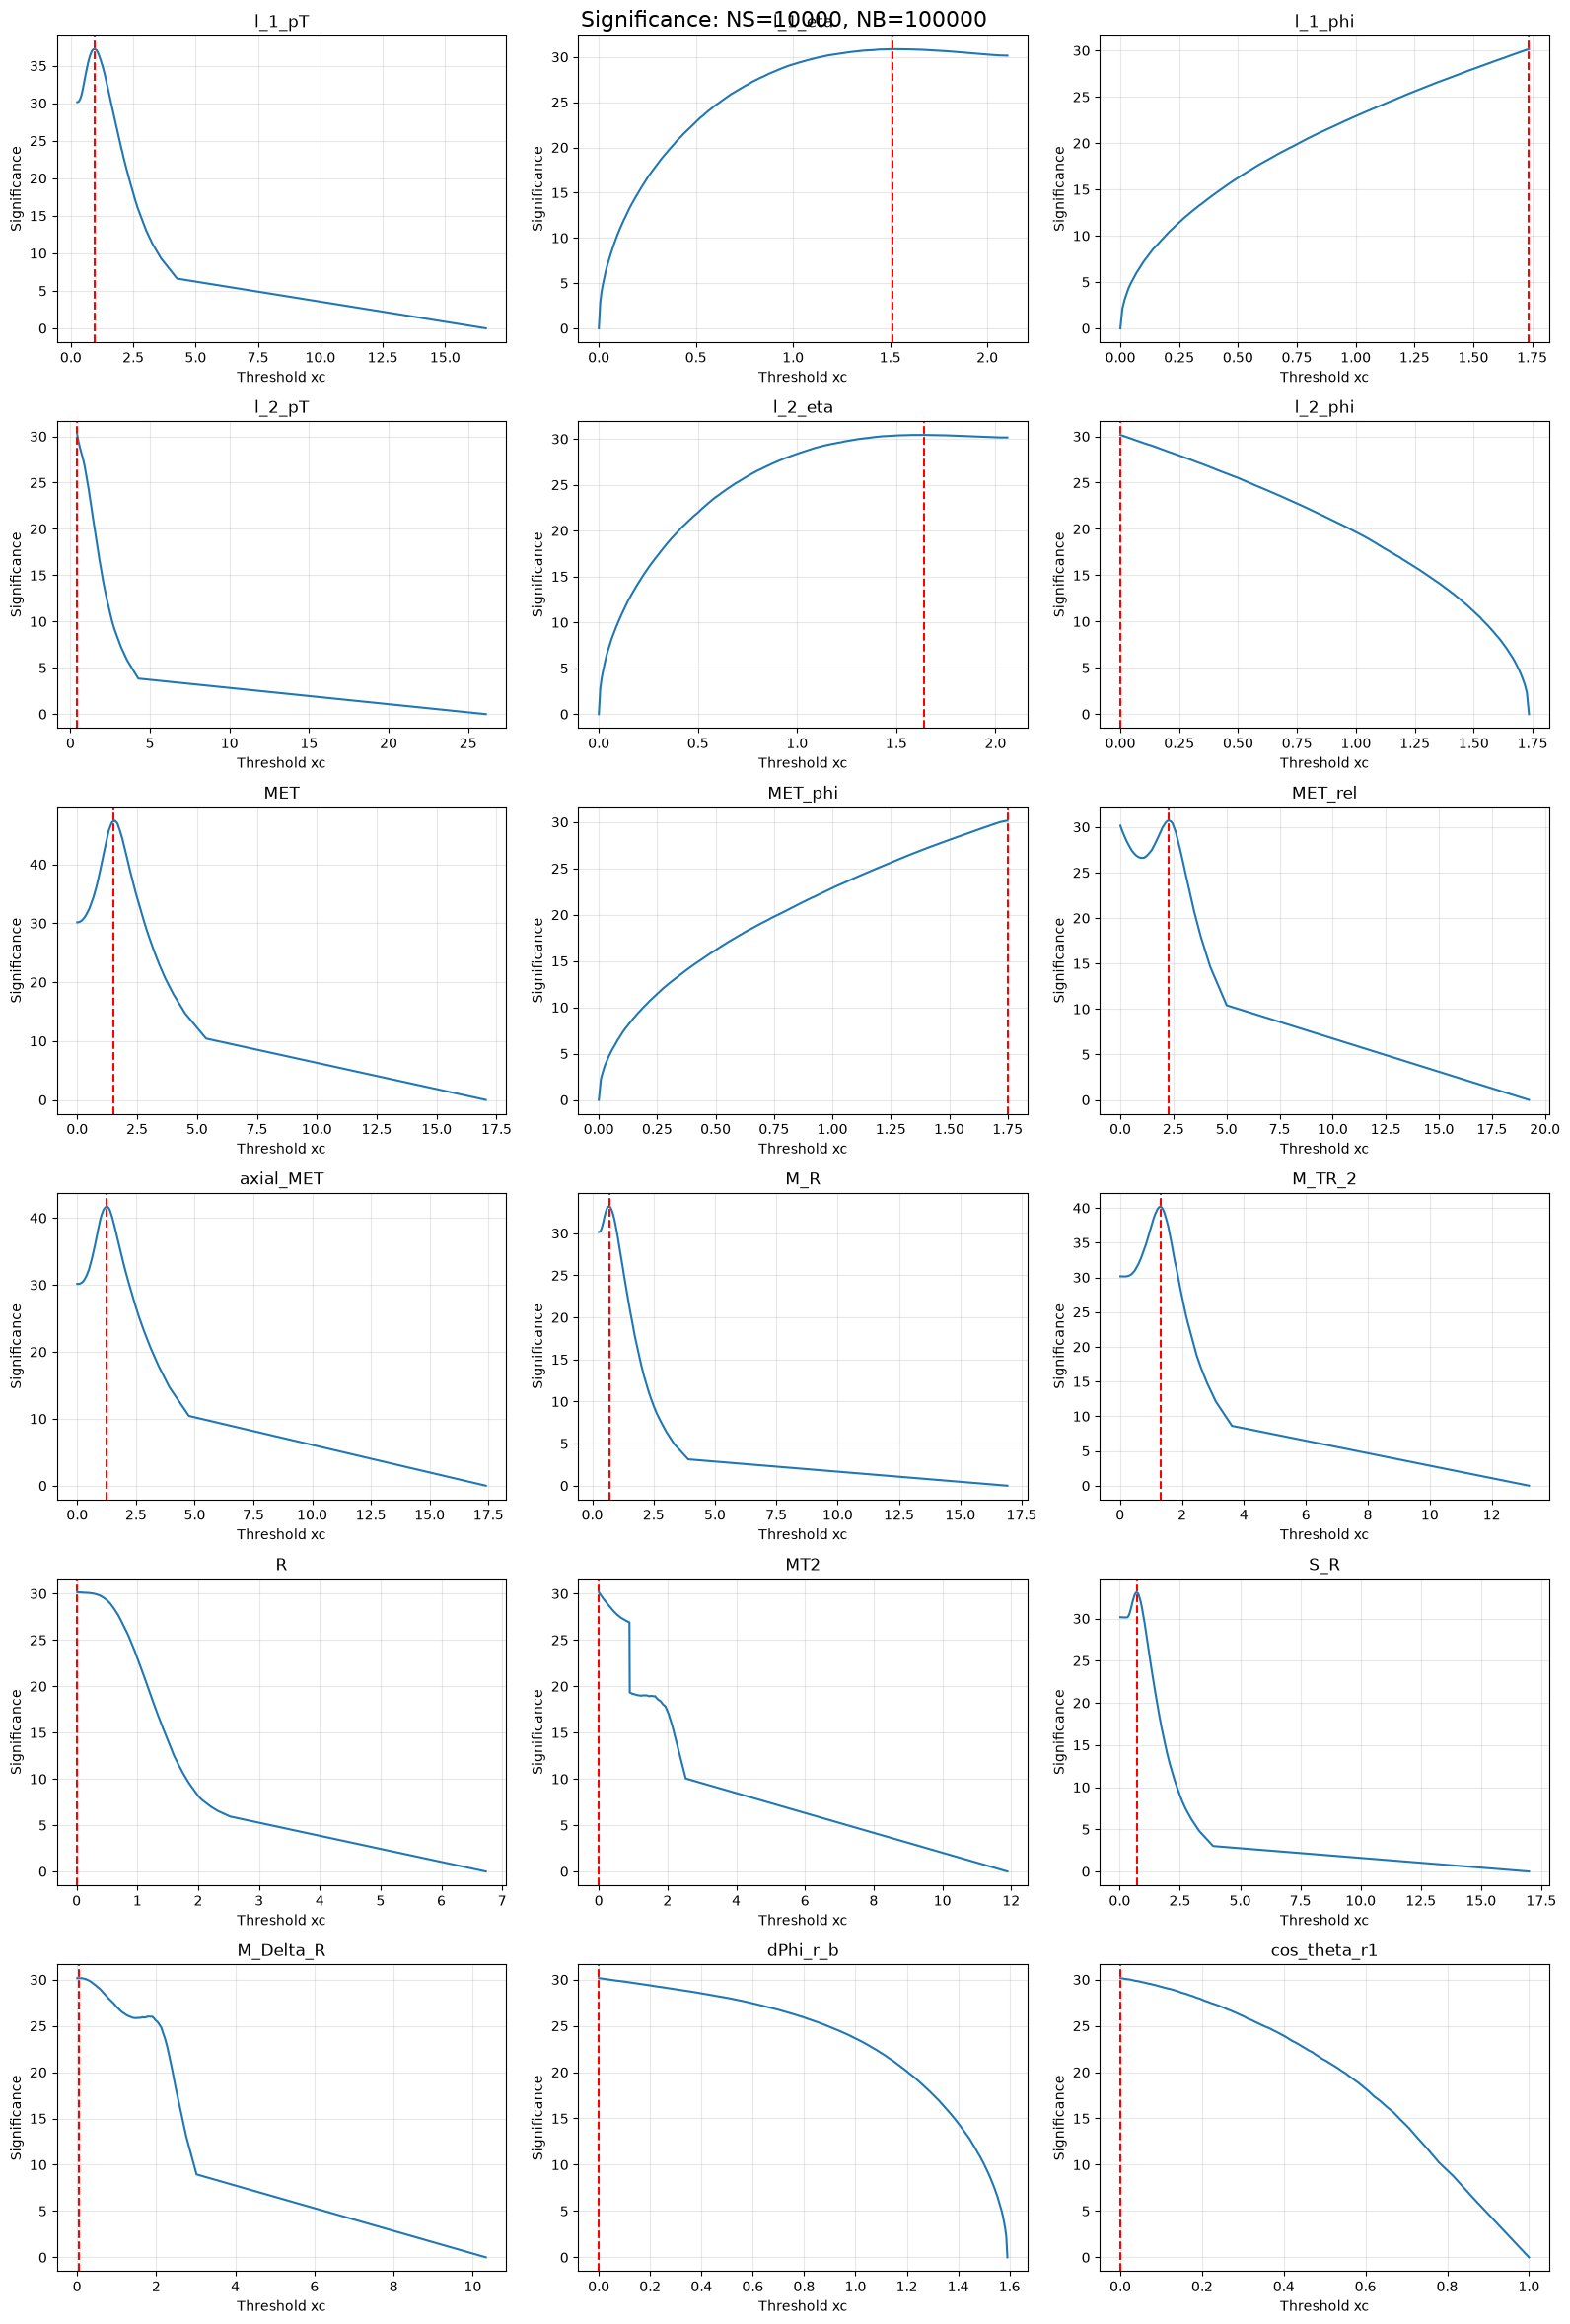


Scenario: NS=10, NB=100
 NS  NB Observable     Criterion  Best Threshold  Max Significance
 10 100        MET        x > xc          1.5250            1.4992
 10 100  axial_MET |x - mu| > xc          1.2470            1.3185
 10 100     M_TR_2        x > xc          1.3054            1.2714
 10 100     l_1_pT        x > xc          0.9588            1.1768
 10 100        M_R        x > xc          0.6851            1.0491

Scenario: NS=100, NB=1000
 NS   NB Observable     Criterion  Best Threshold  Max Significance
100 1000        MET        x > xc          1.5250            4.7408
100 1000  axial_MET |x - mu| > xc          1.2470            4.1695
100 1000     M_TR_2        x > xc          1.3054            4.0205
100 1000     l_1_pT        x > xc          0.9588            3.7213
100 1000        M_R        x > xc          0.6851            3.3177

Scenario: NS=1000, NB=10000
  NS    NB Observable     Criterion  Best Threshold  Max Significance
1000 10000        MET        x > xc    

In [7]:
#5.3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RawNames = [
    "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi"
]

FeatureNames = [
    "MET_rel", "axial_MET", "M_R", "M_TR_2",
    "R", "MT2", "S_R", "M_Delta_R",
    "dPhi_r_b", "cos_theta_r1"
]

columns = ["signal"] + RawNames + FeatureNames

df = pd.read_csv("SUSY-small.csv", header=None, names=columns)

signal_mask = df["signal"].to_numpy() == 1
background_mask = ~signal_mask

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

criteria = dict(zip(
    selection_results["Observable"],
    selection_results["Best Criterion"]
))

mu_values = dict(zip(
    selection_results["Observable"],
    selection_results["mu"]
))

best_results = []

for NS, NB in scenarios:
    fig, axes = plt.subplots(6, 3, figsize=(16, 24))

    for ax, col in zip(axes.ravel(), RawNames + FeatureNames):
        x = df[col].to_numpy()
        criterion = criteria[col]
        mu = mu_values[col]

        if criterion == "x > xc":
            values = x
            greater = True
        elif criterion == "x < xc":
            values = x
            greater = False
        elif criterion == "|x - mu| > xc":
            values = np.abs(x - mu)
            greater = True
        else:
            values = np.abs(x - mu)
            greater = False

        thresholds = np.unique(np.quantile(
            values, np.linspace(0, 1, 201)
        ))

        signal_values = np.sort(values[signal_mask])
        background_values = np.sort(values[background_mask])

        if greater:
            es = 1 - np.searchsorted(
                signal_values, thresholds, side="right"
            ) / len(signal_values)

            eb = 1 - np.searchsorted(
                background_values, thresholds, side="right"
            ) / len(background_values)
        else:
            es = np.searchsorted(
                signal_values, thresholds, side="left"
            ) / len(signal_values)

            eb = np.searchsorted(
                background_values, thresholds, side="left"
            ) / len(background_values)

        S = NS * es
        B = NB * eb

        significance = np.divide(
            S,
            np.sqrt(S + B),
            out=np.zeros_like(S),
            where=(S + B) > 0
        )

        best_index = np.argmax(significance)

        best_results.append({
            "NS": NS,
            "NB": NB,
            "Observable": col,
            "Criterion": criterion,
            "Best Threshold": thresholds[best_index],
            "Max Significance": significance[best_index]
        })

        ax.plot(thresholds, significance)
        ax.axvline(
            thresholds[best_index],
            color="red",
            linestyle="--"
        )
        ax.set_title(col)
        ax.set_xlabel("Threshold xc")
        ax.set_ylabel("Significance")
        ax.grid(alpha=0.3)

    fig.suptitle(
        f"Significance: NS={NS}, NB={NB}",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()

best_results_df = pd.DataFrame(best_results)

for NS, NB in scenarios:
    print(f"\nScenario: NS={NS}, NB={NB}")

    result = best_results_df[
        (best_results_df["NS"] == NS) &
        (best_results_df["NB"] == NB)
    ].sort_values("Max Significance", ascending=False)

    print(result.head(5).round(4).to_string(index=False))


## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [8]:
#6.1

import numpy as np
import pandas as pd

observables = ["MET", "l_1_pT", "M_TR_2"]
scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]

cut_settings = {}

for NS, NB in scenarios:
    subset = best_results_df[
        (best_results_df["NS"] == NS) &
        (best_results_df["NB"] == NB) &
        (best_results_df["Observable"].isin(observables))
    ]

    cuts = []

    for col in observables:
        row = subset[subset["Observable"] == col].iloc[0]
        cuts.append((col, row["Criterion"], float(row["Best Threshold"])))

    cut_settings[(NS, NB)] = cuts

    print(f"\nScenario: NS={NS}, NB={NB}")
    print(pd.DataFrame(
        cuts, columns=["Observable", "Criterion", "Threshold"]
    ).round(4).to_string(index=False))



Scenario: NS=10, NB=100
Observable Criterion  Threshold
       MET    x > xc     1.5250
    l_1_pT    x > xc     0.9588
    M_TR_2    x > xc     1.3054

Scenario: NS=100, NB=1000
Observable Criterion  Threshold
       MET    x > xc     1.5250
    l_1_pT    x > xc     0.9588
    M_TR_2    x > xc     1.3054

Scenario: NS=1000, NB=10000
Observable Criterion  Threshold
       MET    x > xc     1.5250
    l_1_pT    x > xc     0.9588
    M_TR_2    x > xc     1.3054

Scenario: NS=10000, NB=100000
Observable Criterion  Threshold
       MET    x > xc     1.5250
    l_1_pT    x > xc     0.9588
    M_TR_2    x > xc     1.3054


In [9]:
#6.2

def apply_cut(data, column, criterion, threshold):
    x = data[column].to_numpy()
    mu = float(selection_results.loc[
        selection_results["Observable"] == column, "mu"
    ].iloc[0])

    if criterion == "x > xc":
        return x > threshold
    if criterion == "x < xc":
        return x < threshold
    if criterion == "|x - mu| > xc":
        return np.abs(x - mu) > threshold
    return np.abs(x - mu) < threshold

signal = df["signal"].to_numpy() == 1
background = ~signal

cutflow_results = {}

for (NS, NB), cuts in cut_settings.items():
    selected = np.ones(len(df), dtype=bool)
    rows = []

    for step, (col, criterion, threshold) in enumerate(cuts):
        if step > 0:
            selected &= apply_cut(df, col, criterion, threshold)

        es = np.sum(selected & signal) / np.sum(signal)
        eb = np.sum(selected & background) / np.sum(background)

        S = NS * es
        B = NB * eb
        significance = S / np.sqrt(S + B) if S + B > 0 else 0

        rows.append({
            "Selection": "No cuts" if step == 0 else f"{col} {criterion}",
            "Signal Efficiency": es,
            "Background Efficiency": eb,
            "Expected Signal": S,
            "Expected Background": B,
            "Significance": significance
        })

    col, criterion, threshold = cuts[-1]
    selected &= apply_cut(df, col, criterion, threshold)

    es = np.sum(selected & signal) / np.sum(signal)
    eb = np.sum(selected & background) / np.sum(background)
    S, B = NS * es, NB * eb

    rows.append({
        "Selection": f"{col} {criterion}",
        "Signal Efficiency": es,
        "Background Efficiency": eb,
        "Expected Signal": S,
        "Expected Background": B,
        "Significance": S / np.sqrt(S + B) if S + B > 0 else 0
    })

    result = pd.DataFrame(rows)
    cutflow_results[(NS, NB)] = result

    print(f"\nScenario: NS={NS}, NB={NB}")
    print(result.round(4).to_string(index=False))



Scenario: NS=10, NB=100
    Selection  Signal Efficiency  Background Efficiency  Expected Signal  Expected Background  Significance
      No cuts             1.0000                 1.0000          10.0000              100.000        0.9535
l_1_pT x > xc             0.5904                 0.1927           5.9037               19.265        1.1768
M_TR_2 x > xc             0.3320                 0.0455           3.3200                4.548        1.1836
M_TR_2 x > xc             0.3320                 0.0455           3.3200                4.548        1.1836

Scenario: NS=100, NB=1000
    Selection  Signal Efficiency  Background Efficiency  Expected Signal  Expected Background  Significance
      No cuts             1.0000                 1.0000         100.0000            1000.0000        3.0151
l_1_pT x > xc             0.5904                 0.1927          59.0368             192.6502        3.7213
M_TR_2 x > xc             0.3320                 0.0455          33.1999            

Correlation between MET and l_1_pT: 0.3827

Scenario: NS=10, NB=100
          Order  First Threshold  Optimized Second Threshold  Max Significance
MET then l_1_pT           1.5250                      0.2555            1.4992
l_1_pT then MET           0.9588                      1.2358            1.3550


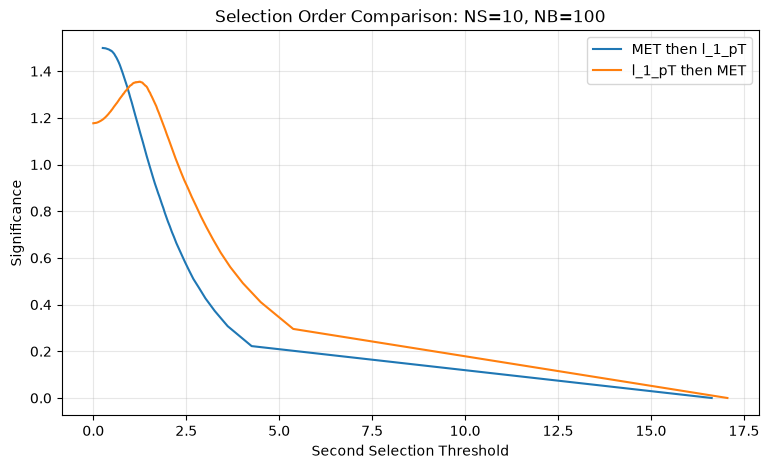


Scenario: NS=100, NB=1000
          Order  First Threshold  Optimized Second Threshold  Max Significance
MET then l_1_pT           1.5250                      0.2555            4.7408
l_1_pT then MET           0.9588                      1.2358            4.2848


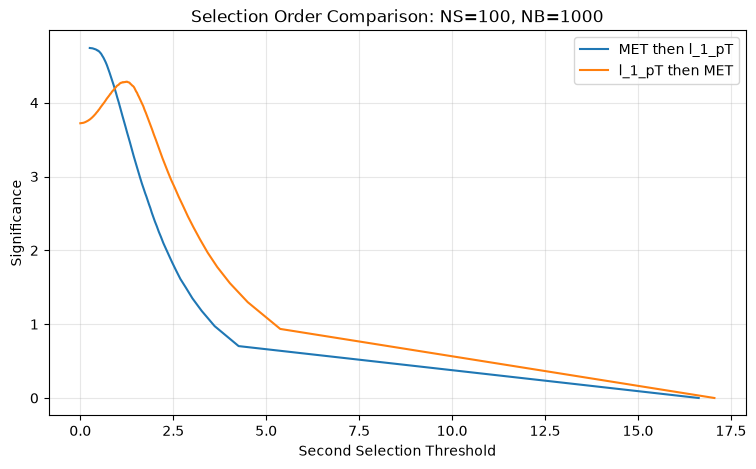


Scenario: NS=1000, NB=10000
          Order  First Threshold  Optimized Second Threshold  Max Significance
MET then l_1_pT           1.5250                      0.2555           14.9916
l_1_pT then MET           0.9588                      1.2358           13.5496


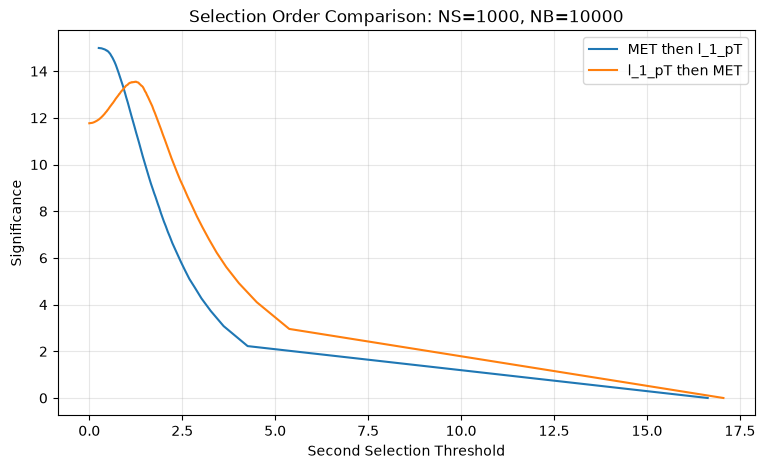


Scenario: NS=10000, NB=100000
          Order  First Threshold  Optimized Second Threshold  Max Significance
MET then l_1_pT           1.5250                      0.2555           47.4077
l_1_pT then MET           0.9588                      1.2358           42.8476


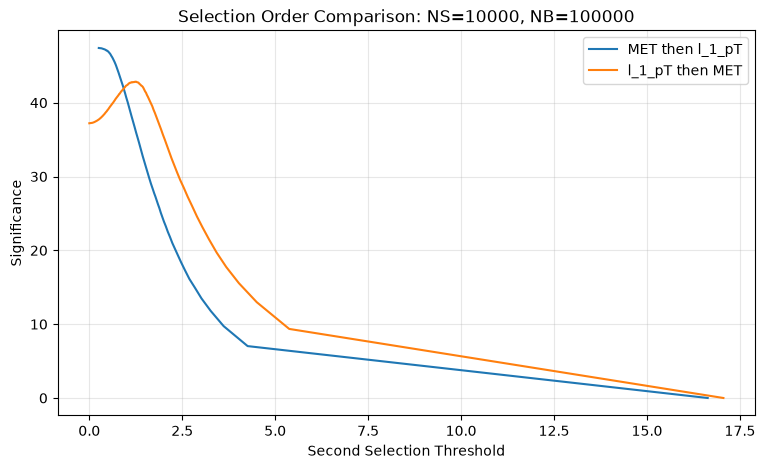

In [10]:
#6.3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

first_var = "MET"
second_var = "l_1_pT"

correlation = df[[first_var, second_var]].corr().iloc[0, 1]
print(f"Correlation between {first_var} and {second_var}: {correlation:.4f}")

def optimize_second(first, second, NS, NB):
    cuts = dict(
        (col, (criterion, threshold))
        for col, criterion, threshold in cut_settings[(NS, NB)]
    )

    first_criterion, first_threshold = cuts[first]
    first_mask = apply_cut(df, first, first_criterion, first_threshold)

    second_criterion, _ = cuts[second]
    mu = float(selection_results.loc[
        selection_results["Observable"] == second, "mu"
    ].iloc[0])

    x = df[second].to_numpy()

    if "mu" in second_criterion:
        values = np.abs(x - mu)
    else:
        values = x

    thresholds = np.unique(np.quantile(
        values, np.linspace(0, 1, 201)
    ))

    sig = df["signal"].to_numpy() == 1
    bkg = ~sig

    sig_values = np.sort(values[first_mask & sig])
    bkg_values = np.sort(values[first_mask & bkg])

    if ">" in second_criterion:
        s_counts = len(sig_values) - np.searchsorted(
            sig_values, thresholds, side="right"
        )
        b_counts = len(bkg_values) - np.searchsorted(
            bkg_values, thresholds, side="right"
        )
    else:
        s_counts = np.searchsorted(
            sig_values, thresholds, side="left"
        )
        b_counts = np.searchsorted(
            bkg_values, thresholds, side="left"
        )

    S = NS * s_counts / sig.sum()
    B = NB * b_counts / bkg.sum()

    significance = np.divide(
        S, np.sqrt(S + B),
        out=np.zeros_like(S, dtype=float),
        where=(S + B) > 0
    )

    best = np.argmax(significance)

    return {
        "Order": f"{first} then {second}",
        "First Threshold": first_threshold,
        "Optimized Second Threshold": thresholds[best],
        "Max Significance": significance[best],
        "thresholds": thresholds,
        "significance": significance
    }

for NS, NB in scenarios:
    forward = optimize_second(first_var, second_var, NS, NB)
    reverse = optimize_second(second_var, first_var, NS, NB)

    print(f"\nScenario: NS={NS}, NB={NB}")

    comparison = pd.DataFrame([
        {k: v for k, v in result.items()
         if k not in ("thresholds", "significance")}
        for result in (forward, reverse)
    ])

    print(comparison.round(4).to_string(index=False))

    plt.figure(figsize=(9, 5))

    for result in (forward, reverse):
        plt.plot(
            result["thresholds"],
            result["significance"],
            label=result["Order"]
        )

    plt.xlabel("Second Selection Threshold")
    plt.ylabel("Significance")
    plt.title(f"Selection Order Comparison: NS={NS}, NB={NB}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



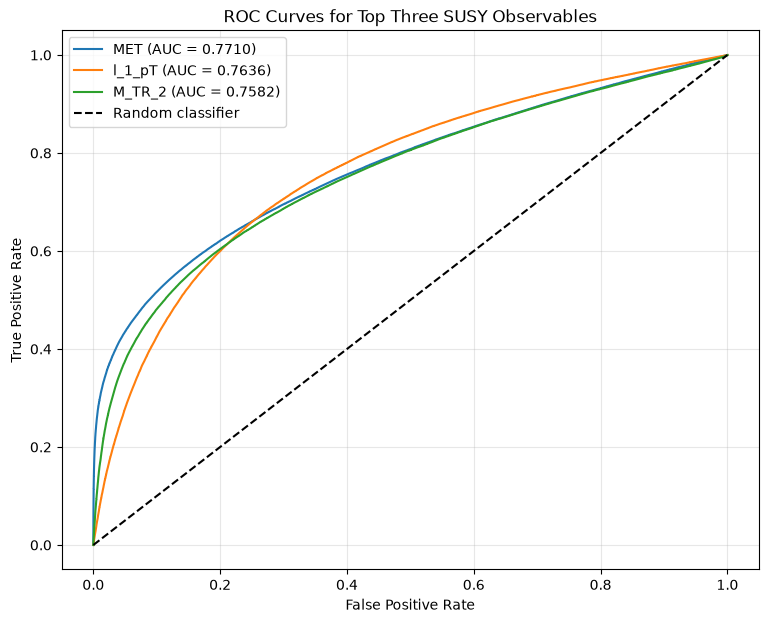

In [11]:
#7.1

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

columns = ["MET", "l_1_pT", "M_TR_2"]
y = df["signal"].astype(int)

plt.figure(figsize=(9, 7))

for col in columns:
    fpr, tpr, thresholds = roc_curve(y, df[col])
    auc = roc_auc_score(y, df[col])
    plt.plot(fpr, tpr, label=f"{col} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Top Three SUSY Observables")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


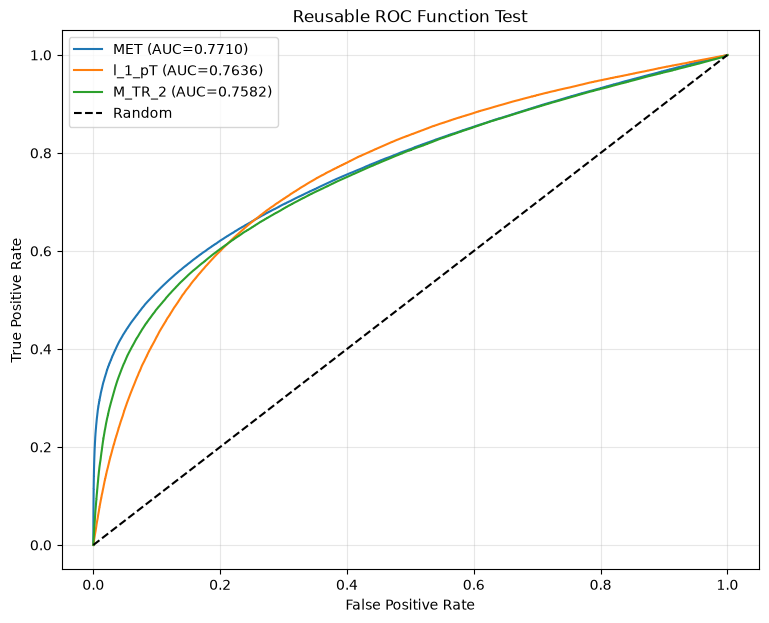

In [12]:
#7.2

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

def plot_roc(data, observables, title, mask=None, criteria=None):
    if mask is None:
        mask = np.ones(len(data), dtype=bool)

    selected = data.loc[mask]
    y = selected["signal"].astype(int)

    if y.nunique() < 2:
        print("Both signal and background are required.")
        return

    plt.figure(figsize=(9, 7))

    for col in observables:
        x = selected[col].to_numpy()
        criterion = criteria.get(col, "x > xc") if criteria else "x > xc"

        if "mu" in criterion:
            mu = data[col].median()
            x = np.abs(x - mu)

        if "<" in criterion:
            x = -x

        fpr, tpr, _ = roc_curve(y, x)
        auc = roc_auc_score(y, x)

        plt.plot(fpr, tpr, label=f"{col} (AUC={auc:.4f})")

    plt.plot([0, 1], [0, 1], "k--", label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_roc(
    df,
    ["MET", "l_1_pT", "M_TR_2"],
    "Reusable ROC Function Test"
)


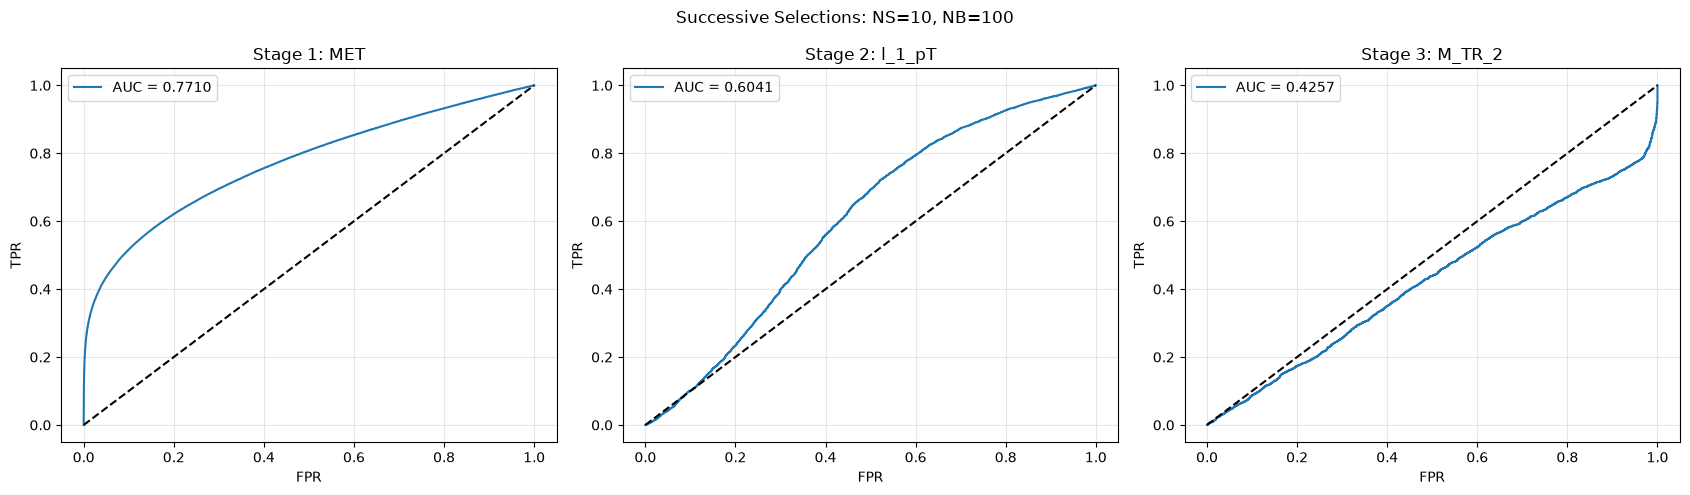

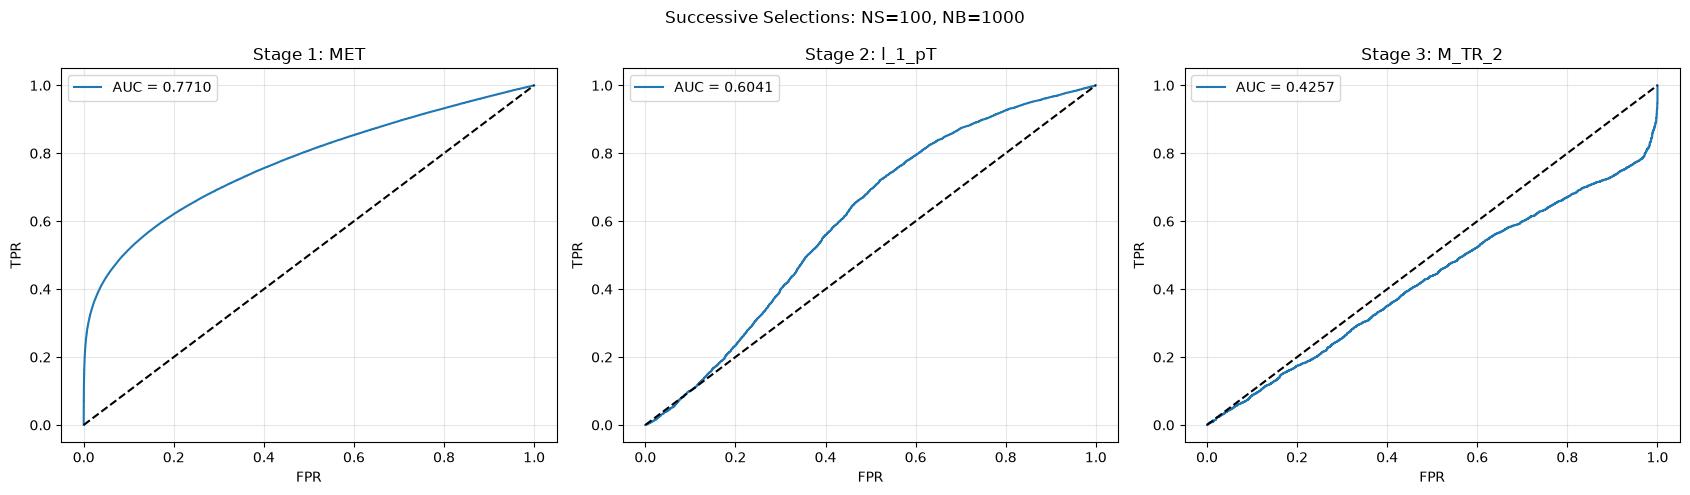

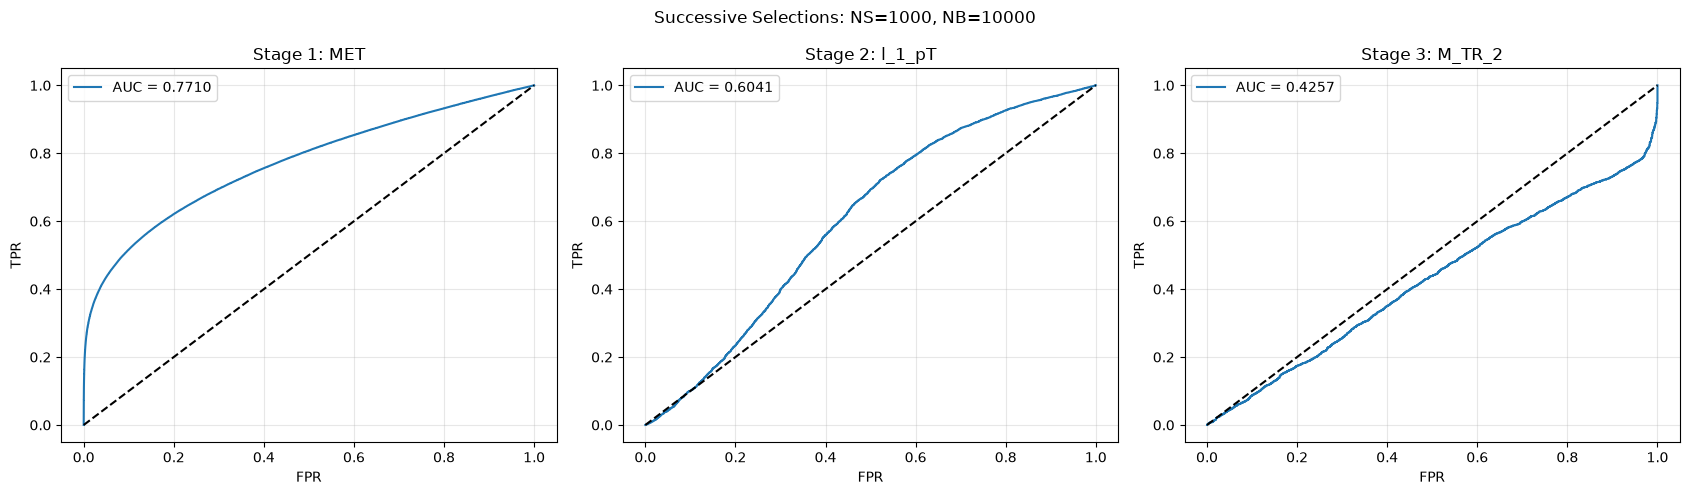

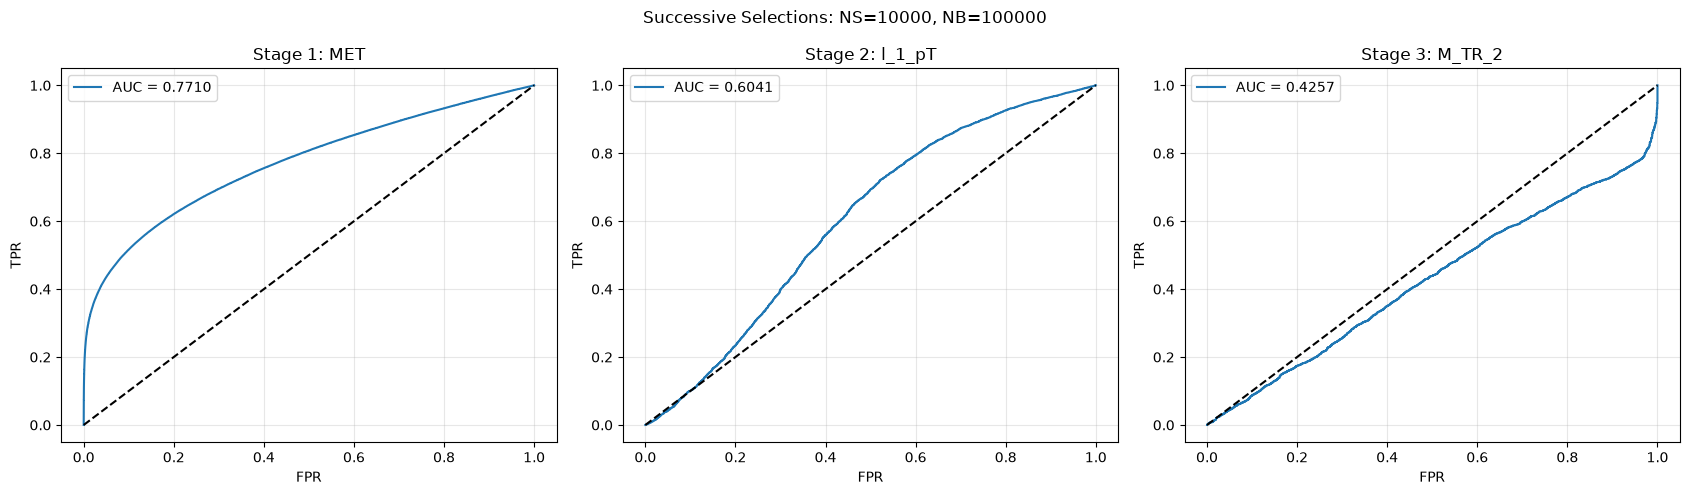

In [13]:
#7.3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

for (NS, NB), cuts in cut_settings.items():
    selected = np.ones(len(df), dtype=bool)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    for i, (col, criterion, threshold) in enumerate(cuts):
        subset = df.loc[selected]
        y = subset["signal"].astype(int)

        if y.nunique() < 2:
            axes[i].text(0.2, 0.5, "Insufficient classes")
            continue

        x = subset[col].to_numpy()

        if "mu" in criterion:
            mu = float(selection_results.loc[
                selection_results["Observable"] == col, "mu"
            ].iloc[0])
            x = np.abs(x - mu)

        if "<" in criterion:
            x = -x

        fpr, tpr, _ = roc_curve(y, x)
        auc = roc_auc_score(y, x)

        axes[i].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
        axes[i].plot([0, 1], [0, 1], "k--")
        axes[i].set_title(f"Stage {i+1}: {col}")
        axes[i].set_xlabel("FPR")
        axes[i].set_ylabel("TPR")
        axes[i].legend()
        axes[i].grid(alpha=0.3)

        selected &= apply_cut(df, col, criterion, threshold)

    fig.suptitle(f"Successive Selections: NS={NS}, NB={NB}")
    plt.tight_layout()
    plt.show()


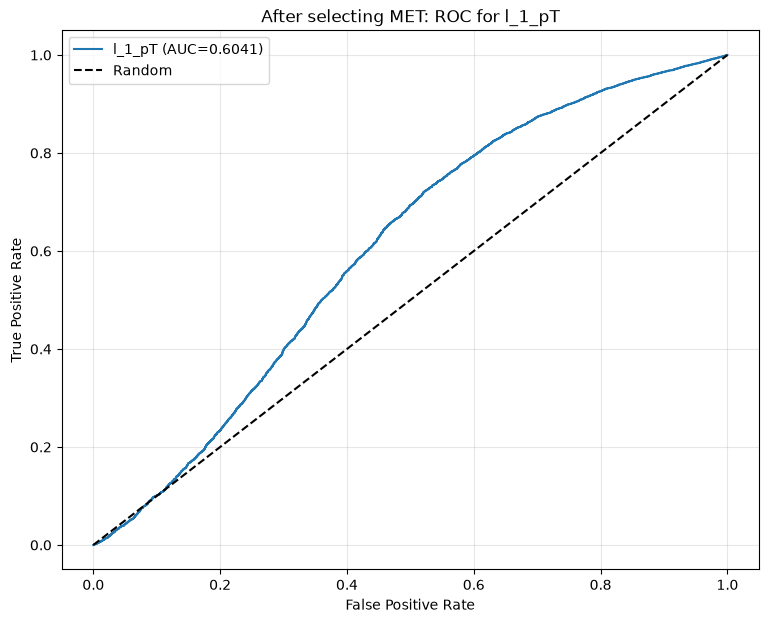

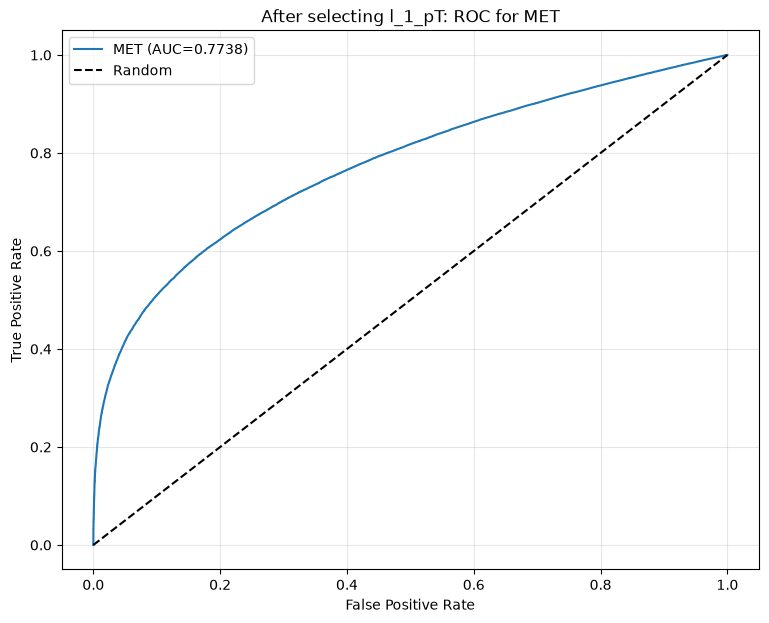

       Order  Step    TPR    FPR  Significance
MET → l_1_pT     1 0.3306 0.0156       14.9916
MET → l_1_pT     2 0.2290 0.0078       13.0767
l_1_pT → MET     1 0.5904 0.1927       11.7677
l_1_pT → MET     2 0.2290 0.0078       13.0767


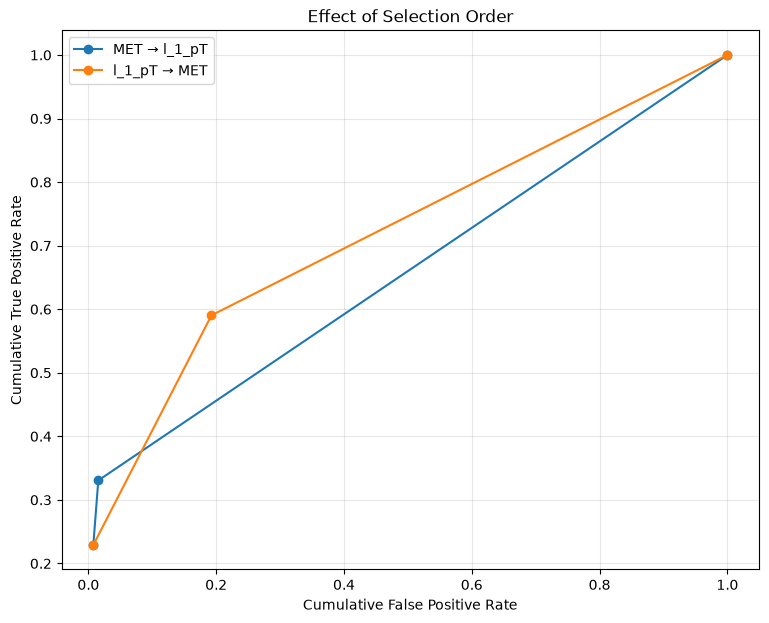


Final TPR difference: 0.0
Final FPR difference: 0.0
Final significance difference: 0.0


In [15]:
#7.4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

NS, NB = 1000, 10000

cuts = {
    col: (criterion, threshold)
    for col, criterion, threshold in cut_settings[(NS, NB)]
}

orders = [
    ["MET", "l_1_pT"],
    ["l_1_pT", "MET"]
]

signal = df["signal"].to_numpy() == 1
background = ~signal

results = []

for order in orders:
    selected = np.ones(len(df), dtype=bool)

    for step, col in enumerate(order, 1):
        criterion, threshold = cuts[col]
        selected &= apply_cut(df, col, criterion, threshold)

        es = np.sum(selected & signal) / np.sum(signal)
        eb = np.sum(selected & background) / np.sum(background)

        S = NS * es
        B = NB * eb
        significance = S / np.sqrt(S + B) if S + B > 0 else 0

        results.append({
            "Order": " → ".join(order),
            "Step": step,
            "TPR": es,
            "FPR": eb,
            "Significance": significance
        })

    next_col = order[1]
    first_col = order[0]
    first_criterion, first_threshold = cuts[first_col]
    mask = apply_cut(df, first_col, first_criterion, first_threshold)

    plot_roc(
        df,
        [next_col],
        f"After selecting {first_col}: ROC for {next_col}",
        mask=mask,
        criteria={next_col: cuts[next_col][0]}
    )

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 7))

for order, group in results_df.groupby("Order", sort=False):
    points = group.sort_values("Step")
    plt.plot(
        [1] + points["FPR"].tolist(),
        [1] + points["TPR"].tolist(),
        marker="o",
        label=order
    )

plt.xlabel("Cumulative False Positive Rate")
plt.ylabel("Cumulative True Positive Rate")
plt.title("Effect of Selection Order")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

first = results_df[
    (results_df["Step"] == 2) &
    (results_df["Order"] == "MET → l_1_pT")
].iloc[0]

second = results_df[
    (results_df["Step"] == 2) &
    (results_df["Order"] == "l_1_pT → MET")
].iloc[0]

print("\nFinal TPR difference:", abs(first["TPR"] - second["TPR"]))
print("Final FPR difference:", abs(first["FPR"] - second["FPR"]))
print("Final significance difference:",
      abs(first["Significance"] - second["Significance"]))
#I compared two selection orders: MET followed by l_1_pT, and l_1_pT followed by MET.

#The intermediate efficiencies and conditional ROC curves can differ because each selection changes the events available for the next step.

#However, when the same fixed thresholds are applied, the final selected events and significance are identical regardless of order. 
#This occurs because the logical AND operation is commutative.

#If the second threshold is reoptimized after applying the first selection, different orders may produce different optimized results 
#because the variables are correlated.


## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [16]:
#8.1

import numpy as np
import pandas as pd

RawNames = [
    "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi"
]

FeatureNames = [
    "MET_rel", "axial_MET", "M_R", "M_TR_2",
    "R", "MT2", "S_R", "M_Delta_R",
    "dPhi_r_b", "cos_theta_r1"
]

observables = RawNames + FeatureNames

df = pd.read_csv(
    "SUSY-small.csv",
    header=None,
    names=["signal"] + observables
)

X = df[observables].to_numpy(dtype=np.float64)
y = df["signal"].to_numpy(dtype=int)

X_bkg = X[y == 0]
X_sig = X[y == 1]

m1 = X_bkg.mean(axis=0)
m2 = X_sig.mean(axis=0)

difference = m2 - m1

SB = np.outer(difference, difference)

centered_bkg = X_bkg - m1
centered_sig = X_sig - m2

SW = centered_bkg.T @ centered_bkg + centered_sig.T @ centered_sig

print("Between-class matrix SB:")
print(pd.DataFrame(SB, index=observables, columns=observables).round(4))

print("\nWithin-class matrix SW:")
print(pd.DataFrame(SW, index=observables, columns=observables).round(4))

print("\nSB shape:", SB.shape)
print("SW shape:", SW.shape)


Between-class matrix SB:
              l_1_pT  l_1_eta  l_1_phi  l_2_pT  l_2_eta  l_2_phi     MET  \
l_1_pT        0.2880   0.0005   0.0005  0.1381   0.0015   0.0004  0.4135   
l_1_eta       0.0005   0.0000   0.0000  0.0002   0.0000   0.0000  0.0007   
l_1_phi       0.0005   0.0000   0.0000  0.0002   0.0000   0.0000  0.0007   
l_2_pT        0.1381   0.0002   0.0002  0.0663   0.0007   0.0002  0.1984   
l_2_eta       0.0015   0.0000   0.0000  0.0007   0.0000   0.0000  0.0022   
l_2_phi       0.0004   0.0000   0.0000  0.0002   0.0000   0.0000  0.0005   
MET           0.4135   0.0007   0.0007  0.1984   0.0022   0.0005  0.5936   
MET_phi      -0.0006  -0.0000  -0.0000 -0.0003  -0.0000  -0.0000 -0.0009   
MET_rel       0.2711   0.0004   0.0004  0.1301   0.0015   0.0003  0.3893   
axial_MET     0.0855   0.0001   0.0001  0.0410   0.0005   0.0001  0.1227   
M_R           0.1823   0.0003   0.0003  0.0875   0.0010   0.0002  0.2618   
M_TR_2        0.2666   0.0004   0.0004  0.1279   0.0014   0.000

Fisher Linear Discriminant Coefficients:
  Observable   Coefficient
      l_1_pT  2.268330e-06
     l_1_eta  5.636884e-09
     l_1_phi  2.104239e-09
      l_2_pT  9.955830e-07
     l_2_eta  3.484522e-09
     l_2_phi  2.707626e-09
         MET  1.651854e-06
     MET_phi  2.742418e-09
     MET_rel  1.397233e-07
   axial_MET  2.642057e-07
         M_R -2.721493e-07
      M_TR_2  1.484657e-07
           R -2.111670e-06
         MT2 -3.240406e-07
         S_R -1.811732e-06
   M_Delta_R  1.693481e-06
    dPhi_r_b -7.509028e-08
cos_theta_r1  5.068604e-06

Signal mean: 5.129253301471715e-06
Background mean: 2.0257872846017633e-06


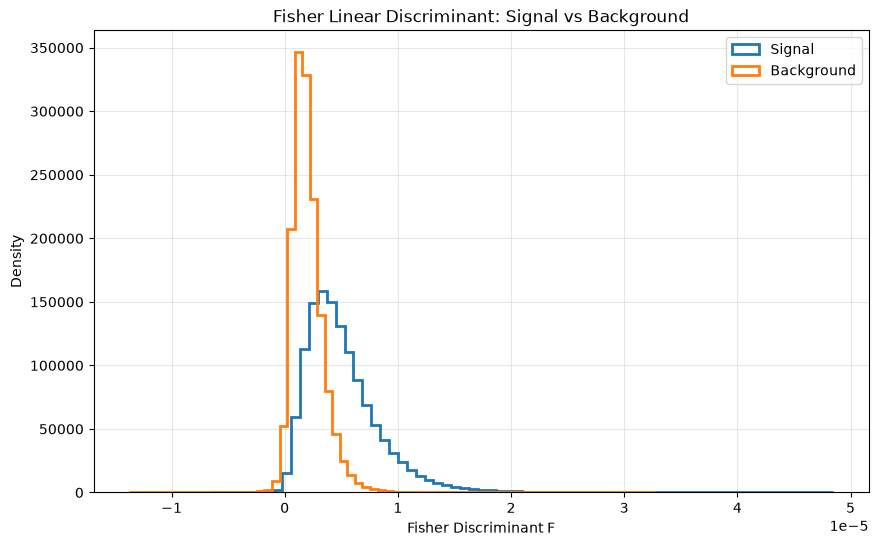

In [17]:
#8.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

w = np.linalg.solve(SW, difference)

F = X @ w

F_sig = F[y == 1]
F_bkg = F[y == 0]

print("Fisher Linear Discriminant Coefficients:")
print(pd.DataFrame({
    "Observable": observables,
    "Coefficient": w
}).to_string(index=False))

print("\nSignal mean:", F_sig.mean())
print("Background mean:", F_bkg.mean())

plt.figure(figsize=(10, 6))

plt.hist(
    F_sig,
    bins=70,
    density=True,
    histtype="step",
    linewidth=2,
    label="Signal"
)

plt.hist(
    F_bkg,
    bins=70,
    density=True,
    histtype="step",
    linewidth=2,
    label="Background"
)

plt.xlabel("Fisher Discriminant F")
plt.ylabel("Density")
plt.title("Fisher Linear Discriminant: Signal vs Background")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


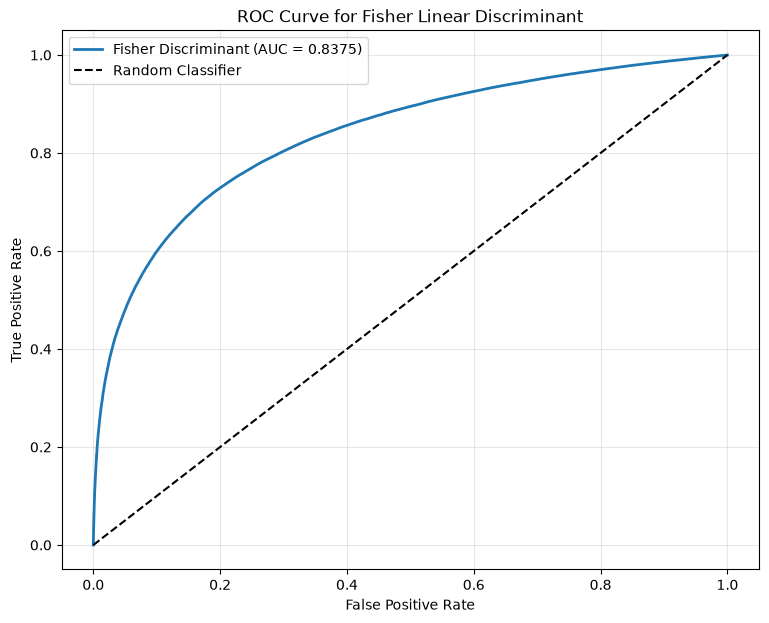

Fisher ROC-AUC: 0.8375


In [18]:
#8.3

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y, F)
auc = roc_auc_score(y, F)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Fisher Discriminant (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Fisher Linear Discriminant")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Fisher ROC-AUC: {auc:.4f}")


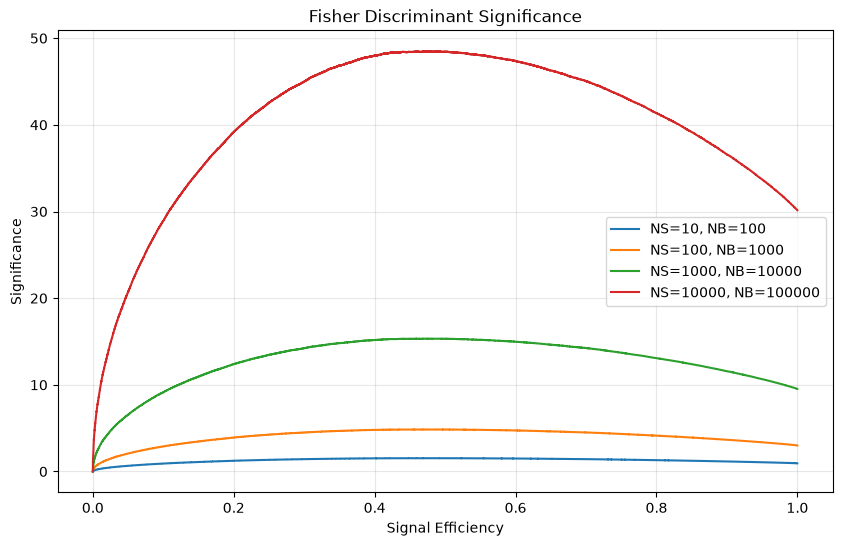

Maximum Significance for Each Scenario:
 Signal  Background  Best Threshold  Signal Efficiency  Background Efficiency  Maximum Significance
     10         100        0.000004           0.491631               0.053742              1.532570
    100        1000        0.000004           0.491631               0.053742              4.846412
   1000       10000        0.000004           0.491631               0.053742             15.325699
  10000      100000        0.000004           0.491631               0.053742             48.464117


In [19]:
#8.4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

fpr, tpr, thresholds = roc_curve(y, F)

results = []

plt.figure(figsize=(10, 6))

for NS, NB in scenarios:
    S = NS * tpr
    B = NB * fpr

    significance = np.divide(
        S,
        np.sqrt(S + B),
        out=np.zeros_like(S),
        where=(S + B) > 0
    )

    best = np.argmax(significance)

    results.append({
        "Signal": NS,
        "Background": NB,
        "Best Threshold": thresholds[best],
        "Signal Efficiency": tpr[best],
        "Background Efficiency": fpr[best],
        "Maximum Significance": significance[best]
    })

    plt.plot(
        tpr,
        significance,
        label=f"NS={NS}, NB={NB}"
    )

plt.xlabel("Signal Efficiency")
plt.ylabel("Significance")
plt.title("Fisher Discriminant Significance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

results_df = pd.DataFrame(results)

print("Maximum Significance for Each Scenario:")
print(results_df.round(6).to_string(index=False))
